# Anime Review Sentiment — Notebook 4: Transformer Fine-tuning, Final Comparison & Business Analysis

Notebook 3 found that a pre-trained RoBERTa-large, used zero-shot, already matches the Linear SVM, and that
fine-tuning a transformer on this corpus was the obvious next experiment. It was ruled out there only because it
needs a GPU. This notebook fine-tunes two transformers on a GPU, compares all five models on the held-out
Dataset B, chooses the model to deploy, and then runs the business analysis.

**At a glance**
- **Fine-tuned RoBERTa-base is the best model: 97.5% accuracy, 0.961 macro-F1 on Dataset B**, against 94.4% /
  0.914 for notebook 3's Linear SVM. Negative-class F1 rises from 0.862 to 0.938
- It makes **21 mistakes on 843 unseen reviews, against the SVM's 47**, and beats zero-shot RoBERTa-large (0.917)
  with about a third of the parameters
- **The cost:** ~109 ms per review on a CPU (SVM ~18 ms), ~12 ms on a GPU, and a 502 MB model instead of 1 MB
- It was chosen on **validation** results (0.966 vs 0.900 for the SVM), before Dataset B was scored

**What this notebook does**
- Fine-tunes **DistilBERT** (~66M parameters) and **RoBERTa-base** (~125M) on the **same training / validation split
  as notebook 3**, keeping the epoch with the best validation macro-F1
- Scores every model **once** on Dataset B: accuracy, macro-F1, negative-class F1 and latency per review
- Chooses the model to deploy from **validation** results and cost, before looking at Dataset B
- Saves the fine-tuned models to `models/`, so `python predict.py --model roberta "..."` works, with an optional
  upload to the Hugging Face Hub so other people can use them without training
- Business layer (moved here from notebook 3): recommendation, challenges, platform health dashboard, aspect analysis

| Input | Output |
|---|---|
| `data/Dataset_A_clean.csv`, `data/clean_artifacts.json` | `models/distilbert-anime-sentiment/`, `models/roberta-base-anime-sentiment/` |
| `data/Dataset_B_raw.csv` (first used in Section 8) | `docs/results/dataset_b_results.csv`, charts in `docs/images/` |
| `data/final_sentiment_model.joblib` (notebook 3) | The results table in `README.md` |

**Hardware.** Fine-tuning needs an NVIDIA GPU with CUDA. This notebook was developed on an RTX 4060 Laptop GPU
(8 GB) with fp16 mixed precision. Each training cell prints how long it took.
**No GPU?** If the fine-tuned models are already in `models/`, or on the Hugging Face Hub (see `HUB_MODEL_IDS` in
`predict.py`), training is skipped and the rest of the notebook runs on a CPU.

**Pipeline:** 1. Scraping → 2. Data Preparation → 3. Modelling & Evaluation → **4. Fine-tuning, Comparison & Business**

## 1. Setup & configuration

In [1]:
# Imports

import os, json, time, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import torch
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm
transformers.logging.set_verbosity_error()   # hides "sequence longer than 512" notices: long reviews are cut on purpose

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import joblib
from IPython.display import display, Markdown

# predict.py is the project's prediction module. Its frozen cleaning (identical to notebook 3) and its
# head+tail encoding are reused here, so training, evaluation and prediction all prepare text the same way.
import predict as P

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

torch 2.11.0+cu128 | transformers 5.22.2


In [2]:
# Configuration

DATA_DIR     = "data"
MODELS_DIR   = P.MODELS_DIR            # models/ in the project folder
RANDOM_STATE = 42                      # same seed as notebooks 1-3, so the validation split is the same

QUICK_RUN = False   # True: 1 epoch on 2,000 training reviews, to test the notebook end to end in a few minutes.
                    #       Quick-run models go to models/_quick_run/, and README/docs are not touched.
RETRAIN   = False   # False: reuse a fine-tuned model already in models/ (or on the Hub) instead of training again

MAX_LENGTH  = P.MAX_LENGTH             # 512 tokens, the most either model can read
HEAD_TOKENS = P.HEAD_TOKENS            # long reviews keep their first 128 + last 382 tokens (Section 3)
FP16        = True                     # mixed precision on the GPU: faster, and about half the memory

FINETUNE = {
    "distilbert": dict(checkpoint="distilbert-base-uncased", label="DistilBERT (fine-tuned)",
                       epochs=3, lr=5e-5, batch_size=16, grad_accum=1),
    "roberta":    dict(checkpoint="roberta-base",            label="RoBERTa-base (fine-tuned)",
                       epochs=3, lr=2e-5, batch_size=8,  grad_accum=2),   # effective batch 16
}
WARMUP_RATIO = 0.10      # learning rate ramps up over the first 10% of steps, then decays linearly to 0
WEIGHT_DECAY = 0.01
PATIENCE     = 1         # stop when validation macro-F1 hasn't improved for this many epochs
EVAL_BATCH   = 64        # lower it if evaluation runs out of GPU memory

# Notebook 3's zero-shot benchmarks, re-scored here so all five models sit in one table
ZERO_SHOT = {
    "distilbert_zs":    dict(checkpoint="distilbert-base-uncased-finetuned-sst-2-english",
                             label="DistilBERT (zero-shot)"),
    "roberta_large_zs": dict(checkpoint="siebert/sentiment-roberta-large-english",
                             label="RoBERTa-large (zero-shot)"),
}

LATENCY_SAMPLE     = 200   # Dataset B reviews timed one at a time on the GPU
CPU_LATENCY_SAMPLE = 50    # ... and on the CPU (RoBERTa-large takes ~0.6 s each). 0 skips the CPU timing
UPDATE_README      = True  # rewrite the results table in README.md with this run's numbers

if QUICK_RUN:
    MODELS_DIR = os.path.join(MODELS_DIR, "_quick_run")
    for _cfg in FINETUNE.values():
        _cfg["epochs"] = 1
    LATENCY_SAMPLE, CPU_LATENCY_SAMPLE, UPDATE_README = 30, 5, False
WRITE_DOCS = not QUICK_RUN               # charts + results CSV in docs/

DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_FP16 = FP16 and DEVICE.type == "cuda"

def set_seed(seed=RANDOM_STATE):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} ({props.total_memory / 1e9:.1f} GB) | fp16: {USE_FP16}")
else:
    print("No CUDA GPU found: training is only possible if saved models already exist (see the intro).")
print(f"Models folder: {MODELS_DIR}" + ("   [QUICK RUN]" if QUICK_RUN else ""))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU (8.6 GB) | fp16: True
Models folder: c:\Users\surgl\School\Anime_reviews_TSA\models


## 2. Data — the same splits as notebook 3

- **Training / validation:** notebook 3's stratified 80/20 split of Dataset A, with the same seed. The transformers
  learn from the training part; the validation part picks the best epoch and the model to deploy.
- **Dataset B:** cleaned exactly as in notebook 3 (same de-duplication, label rule and frozen artifacts), giving the
  same test reviews. It is scored once, in Section 8.

The transformers read the **raw** review text, as the zero-shot benchmarks did: their tokenisers are built for
natural language, and the SVM's aggressive cleaning (stop-word and name removal) would throw away context they
can use. The SVM still gets its cleaned text.

In [3]:
# Step 1 — Dataset A and notebook 3's train/validation split

with open(os.path.join(DATA_DIR, "clean_artifacts.json"), encoding="utf-8") as f:
    META_COLS = json.load(f)["keep_meta"]

df = pd.read_csv(os.path.join(DATA_DIR, "Dataset_A_clean.csv"))
df["clean_text"]  = df["clean_text"].fillna("")
df["review_text"] = df["review_text"].fillna("").astype(str)
y = df["sentiment"].values

# Notebook 3 calls train_test_split(X, y, test_size=0.20, stratify=y, random_state=42). The rows it picks
# depend only on the number of rows, the labels and the seed, so splitting the row index the same way
# reproduces exactly the same training and validation rows.
train_idx, val_idx = train_test_split(df.index.values, test_size=0.20, stratify=y,
                                      random_state=RANDOM_STATE)
if QUICK_RUN:
    train_idx = train_test_split(train_idx, train_size=2000, stratify=y[train_idx],
                                 random_state=RANDOM_STATE)[0]
    val_idx = train_test_split(val_idx, train_size=500, stratify=y[val_idx],
                               random_state=RANDOM_STATE)[0]

tr_text, va_text = df.loc[train_idx, "review_text"].tolist(), df.loc[val_idx, "review_text"].tolist()
y_tr, y_va = y[train_idx], y[val_idx]
print(f"Train: {len(train_idx):,}   Validation: {len(val_idx):,}")
print(f"Positive rate - train: {y_tr.mean():.3f} | validation: {y_va.mean():.3f}")

Train: 12,816   Validation: 3,205
Positive rate - train: 0.804 | validation: 0.804


In [4]:
# Step 2 — Dataset B, cleaned exactly as in notebook 3 (Step 8b)

dfB = pd.read_csv(os.path.join(DATA_DIR, "Dataset_B_raw.csv"))
dfB = dfB.drop_duplicates(subset=["anime_id", "review_text"]).reset_index(drop=True)
dfB["sentiment"] = dfB["rating"].apply(lambda r: 1 if r >= 7 else (0 if r <= 4 else np.nan))
dfB = dfB.dropna(subset=["sentiment"]).copy()
dfB["sentiment"] = dfB["sentiment"].astype(int)

t0 = time.time()
dfB["clean_text"] = dfB["review_text"].apply(P.clean_text)            # frozen artifacts, as in notebook 3
dfB = pd.concat([dfB, pd.DataFrame([P.meta_features(t) for t in dfB["review_text"]], index=dfB.index)], axis=1)
dfB = dfB[dfB["clean_text"].str.split().str.len() >= 3].reset_index(drop=True)

B_text = dfB["review_text"].fillna("").astype(str).tolist()          # raw text, for the transformers
XB     = dfB[["clean_text"] + META_COLS]                              # cleaned text, for the SVM
yB     = dfB["sentiment"].values
print(f"Dataset B: {len(dfB):,} test reviews (cleaned in {time.time()-t0:.0f}s), "
      f"positive rate {yB.mean():.3f}")

Dataset B: 843 test reviews (cleaned in 30s), positive rate 0.804


## 3. Long reviews — what fits in 512 tokens?

Both transformers read at most **512 tokens** (about 380 words), and anime reviews are often much longer. The
zero-shot pipelines in notebook 3 kept the first 512 tokens. That drops the end of the review, which is usually
where the reviewer gives their verdict ("overall, 6/10, only for fans…").

**Choice: head + tail truncation.** A review that is too long keeps its **first 128 and last 382 tokens**. Sun et
al. (2019, *How to Fine-Tune BERT for Text Classification?*) compared ways of cutting long IMDb reviews and found
this split worked best. The function is `encode_head_tail()` in `predict.py`. Training and prediction both call
it, so the model never sees text cut differently from how it was trained — the same *train/serve skew* that
notebook 3 avoided by freezing the cleaning artifacts.

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokens per review - median 479, mean 697, 90th percentile 1462
Reviews longer than 512 tokens: 47.2%  -> these are cut with head+tail truncation


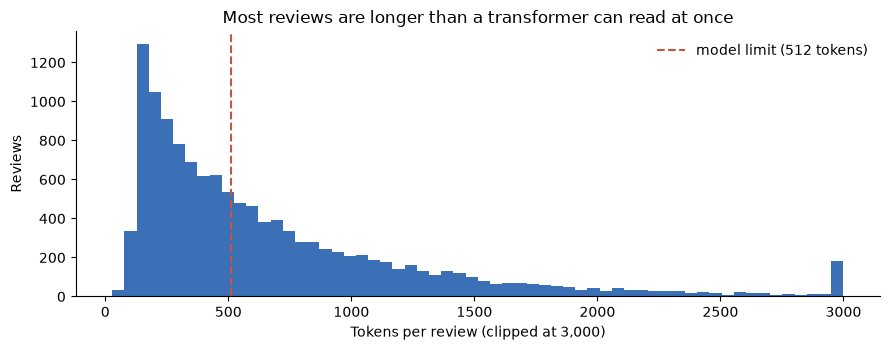

In [5]:
# Step 3 — review length in tokens (RoBERTa's tokeniser; DistilBERT's gives similar counts)

_tok = AutoTokenizer.from_pretrained(FINETUNE["roberta"]["checkpoint"])
tok_len = np.array([len(ids) for ids in _tok(tr_text, truncation=False)["input_ids"]])
over = (tok_len > MAX_LENGTH).mean()
print(f"Tokens per review - median {np.median(tok_len):.0f}, mean {tok_len.mean():.0f}, "
      f"90th percentile {np.percentile(tok_len, 90):.0f}")
print(f"Reviews longer than {MAX_LENGTH} tokens: {over:.1%}  -> these are cut with head+tail truncation")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.clip(tok_len, 0, 3000), bins=60, color="#3B6FB6")
ax.axvline(MAX_LENGTH, ls="--", color="#C4553E", label=f"model limit ({MAX_LENGTH} tokens)")
ax.set_xlabel("Tokens per review (clipped at 3,000)"); ax.set_ylabel("Reviews")
ax.set_title("Most reviews are longer than a transformer can read at once")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
del _tok

## 4. The fine-tuning loop

A plain PyTorch loop rather than Hugging Face's `Trainer`, so every choice is visible:

| Choice | Why |
|---|---|
| **Class-weighted cross-entropy** | The data is 4 : 1 positive. The weights use the same formula as `class_weight="balanced"` in notebook 3, so the comparison with the SVM is like-for-like |
| **AdamW, warm-up then linear decay** | The standard recipe for fine-tuning BERT-style models. Warm-up stops the first large updates from wrecking the pre-trained weights |
| **fp16 mixed precision** (`torch.autocast` + `GradScaler`) | About twice as fast on an RTX GPU, and half the activation memory, which is what lets 512-token batches fit in 8 GB |
| **Gradient accumulation** | RoBERTa-base fits 8 reviews per step; two steps are added up for an effective batch of 16 |
| **Gradient clipping at 1.0** | Guards against the occasional exploding update |
| **Best epoch by validation macro-F1** | The same metric notebook 3 ranks on. Early stopping ends training after `PATIENCE` epochs without improvement |

Every epoch is scored on the validation split, and only the best epoch is saved to `models/<name>/`, together
with `training_info.json` (settings, per-epoch history and validation scores). If that file already exists and
`RETRAIN = False`, the saved model is reused and training is skipped.

In [6]:
# Step 4 — fine-tuning helpers

def class_weights(labels):
    # n_samples / (n_classes * count): identical to scikit-learn's class_weight="balanced"
    counts = np.bincount(labels, minlength=2)
    return torch.tensor(len(labels) / (2 * counts), dtype=torch.float)

def scores(y_true, pred):
    return {"Accuracy": round(accuracy_score(y_true, pred), 4),
            "Macro-F1": round(f1_score(y_true, pred, average="macro"), 4),
            "F1 (neg)": round(f1_score(y_true, pred, pos_label=0), 4),
            "F1 (pos)": round(f1_score(y_true, pred, pos_label=1), 4)}

def fine_tune(key, cfg):
    # Fine-tune one checkpoint; save the best epoch to MODELS_DIR/<name>/; return training_info
    out_dir = os.path.join(MODELS_DIR, P.TRANSFORMER_MODELS[key])
    os.makedirs(out_dir, exist_ok=True)
    set_seed()
    tokenizer = AutoTokenizer.from_pretrained(cfg["checkpoint"])
    model = AutoModelForSequenceClassification.from_pretrained(
        cfg["checkpoint"], num_labels=2,
        id2label={0: "negative", 1: "positive"}, label2id={"negative": 0, "positive": 1}).to(DEVICE)

    t0 = time.time()
    train_ids = P.encode_head_tail(tokenizer, tr_text, MAX_LENGTH, HEAD_TOKENS)
    val_ids   = P.encode_head_tail(tokenizer, va_text, MAX_LENGTH, HEAD_TOKENS)
    print(f"Tokenised {len(train_ids):,} + {len(val_ids):,} reviews in {time.time()-t0:.0f}s")

    bs, accum, epochs = cfg["batch_size"], cfg["grad_accum"], cfg["epochs"]
    batches_per_epoch = math.ceil(len(train_ids) / bs)
    total_steps = math.ceil(batches_per_epoch / accum) * epochs

    # no weight decay on biases and LayerNorm weights (the 1-D parameters)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(
        [{"params": [p for p in params if p.ndim >= 2], "weight_decay": WEIGHT_DECAY},
         {"params": [p for p in params if p.ndim < 2],  "weight_decay": 0.0}], lr=cfg["lr"])
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    scaler  = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights(y_tr).to(DEVICE))
    rng = np.random.default_rng(RANDOM_STATE)

    history, best, bad_epochs, t_start = [], None, 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        order = rng.permutation(len(train_ids))
        batches = [order[i:i + bs] for i in range(0, len(order), bs)]
        running = 0.0
        optimizer.zero_grad(set_to_none=True)
        bar = tqdm(batches, desc=f"{key} - epoch {epoch}/{epochs}", leave=False)
        for step, idx in enumerate(bar, 1):
            batch  = P.pad_batch([train_ids[i] for i in idx], tokenizer.pad_token_id, DEVICE)
            labels = torch.as_tensor(y_tr[idx], dtype=torch.long, device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_FP16):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss / accum).backward()
            if step % accum == 0 or step == len(batches):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
            running += loss.item()
            if step % 25 == 0:
                bar.set_postfix(loss=f"{running / step:.4f}")

        # ---- score the validation split after every epoch
        val_prob = P.predict_proba_ids(model, val_ids, tokenizer.pad_token_id, DEVICE, EVAL_BATCH, USE_FP16)
        val_pred = (val_prob >= 0.5).astype(int)
        row = {"epoch": epoch, "train_loss": round(running / len(batches), 4),
               "val_loss": round(log_loss(y_va, np.c_[1 - val_prob, val_prob]), 4),
               **{f"val_{k}": v for k, v in scores(y_va, val_pred).items()},
               "minutes": round((time.time() - t_start) / 60, 1)}
        history.append(row)
        improved = best is None or row["val_Macro-F1"] > best["val_Macro-F1"]
        print(f"epoch {epoch}: train loss {row['train_loss']:.4f} | val loss {row['val_loss']:.4f} | "
              f"val macro-F1 {row['val_Macro-F1']:.4f} | val F1(neg) {row['val_F1 (neg)']:.4f} | "
              f"{row['minutes']} min" + ("   <- best so far, saved" if improved else ""))
        if improved:
            best, bad_epochs = row, 0
            model.save_pretrained(out_dir)
            tokenizer.save_pretrained(out_dir)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"No improvement for {PATIENCE} epoch(s): stopping early.")
                break

    info = {
        "name": P.TRANSFORMER_MODELS[key], "base_checkpoint": cfg["checkpoint"], "label": cfg["label"],
        "max_length": MAX_LENGTH, "head_tokens": HEAD_TOKENS, "fp16": USE_FP16,
        "epochs_max": epochs, "best_epoch": best["epoch"], "lr": cfg["lr"],
        "batch_size": bs, "grad_accum": accum, "warmup_ratio": WARMUP_RATIO, "weight_decay": WEIGHT_DECAY,
        "class_weights": [round(float(w), 4) for w in class_weights(y_tr)],
        "n_train": len(train_ids), "n_val": len(val_ids), "random_state": RANDOM_STATE,
        "train_minutes": round((time.time() - t_start) / 60, 1),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
        "val_scores": {k.replace("val_", ""): v for k, v in best.items() if k.startswith("val_") and k != "val_loss"},
        "history": history, "quick_run": QUICK_RUN,
    }
    with open(os.path.join(out_dir, "training_info.json"), "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2)
    print(f"Best epoch {info['best_epoch']} saved to {out_dir} ({info['train_minutes']} min in total)")
    del model, optimizer, scaler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return info

def get_finetuned(key):
    # Reuse a saved model unless RETRAIN; otherwise fine-tune. Returns (source, training_info).
    if not RETRAIN:
        src = P.resolve_model_source(key, models_dir=MODELS_DIR, allow_hub=not QUICK_RUN)
        if src is not None:
            print(f"Using the saved {key} model from {src}  (set RETRAIN = True to train again)")
            return src, P.load_training_info(src)
    if DEVICE.type != "cuda":
        raise RuntimeError(
            "Fine-tuning needs a CUDA GPU and no saved model was found. Either run this on a GPU machine, "
            "or download the fine-tuned models: set HUB_MODEL_IDS in predict.py (see the README).")
    info = fine_tune(key, FINETUNE[key])
    return os.path.join(MODELS_DIR, P.TRANSFORMER_MODELS[key]), info

FT_SOURCE, FT_INFO = {}, {}
print("Class weights (negative, positive):", class_weights(y_tr).numpy().round(3))

Class weights (negative, positive): [2.55  0.622]


## 5. Fine-tune DistilBERT

DistilBERT is BERT compressed to 6 layers (~66M parameters), about 60% faster with most of BERT's accuracy. The
starting point is the general `distilbert-base-uncased` checkpoint, **not** the movie-review model used zero-shot
in notebook 3, so any improvement comes from the anime reviews themselves.

In [7]:
# Step 5 — fine-tune DistilBERT (skipped if a saved model exists and RETRAIN = False)

FT_SOURCE["distilbert"], FT_INFO["distilbert"] = get_finetuned("distilbert")
pd.DataFrame(FT_INFO["distilbert"].get("history", [])).set_index("epoch")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

W1112 13:01:01.052000 43624 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

distilbert - epoch 3/3:   0%|          | 0/801 [00:00<?, ?it/s]

epoch 3: train loss 0.0570 | val loss 0.1955 | val macro-F1 0.9321 | val F1(neg) 0.8905 | 9.8 min
No improvement for 1 epoch(s): stopping early.
Best epoch 2 saved to c:\Users\surgl\School\Anime_reviews_TSA\models\distilbert-anime-sentiment (9.8 min in total)


,train_loss,val_loss,val_Accuracy,val_Macro-F1,val_F1 (neg),val_F1 (pos),minutes
epoch,,,,,,,
1,0.3579,0.1817,0.9417,0.9032,0.8422,0.9642,3.3
2,0.1463,0.1407,0.9582,0.9334,0.8928,0.9740,6.6
3,0.0570,0.1955,0.9576,0.9321,0.8905,0.9737,9.8


## 6. Fine-tune RoBERTa-base

RoBERTa is BERT pre-trained for longer, on ten times more text, and without BERT's next-sentence task; it
usually beats BERT on classification. `roberta-base` (12 layers, ~125M parameters) is the largest model that
fine-tunes comfortably at 512 tokens on an 8 GB GPU. RoBERTa-large (355M), the zero-shot benchmark, would need
much smaller batches and several times longer.

In [8]:
# Step 6 — fine-tune RoBERTa-base (skipped if a saved model exists and RETRAIN = False)

FT_SOURCE["roberta"], FT_INFO["roberta"] = get_finetuned("roberta")
pd.DataFrame(FT_INFO["roberta"].get("history", [])).set_index("epoch")

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Tokenised 12,816 + 3,205 reviews in 37s


roberta - epoch 1/3:   0%|          | 0/1602 [00:00<?, ?it/s]

epoch 1: train loss 0.3215 | val loss 0.1104 | val macro-F1 0.9487 | val F1(neg) 0.9179 | 6.3 min   <- best so far, saved


... (5 outputs left out)

epoch 3: train loss 0.0614 | val loss 0.1161 | val macro-F1 0.9661 | val F1(neg) 0.9457 | 17.9 min   <- best so far, saved


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best epoch 3 saved to c:\Users\surgl\School\Anime_reviews_TSA\models\roberta-base-anime-sentiment (18.0 min in total)


,train_loss,val_loss,val_Accuracy,val_Macro-F1,val_F1 (neg),val_F1 (pos),minutes
epoch,,,,,,,
1,0.3215,0.1104,0.9672,0.9487,0.9179,0.9795,6.3
2,0.1211,0.1142,0.9744,0.9595,0.9349,0.9841,12.7
3,0.0614,0.1161,0.9785,0.9661,0.9457,0.9866,17.9


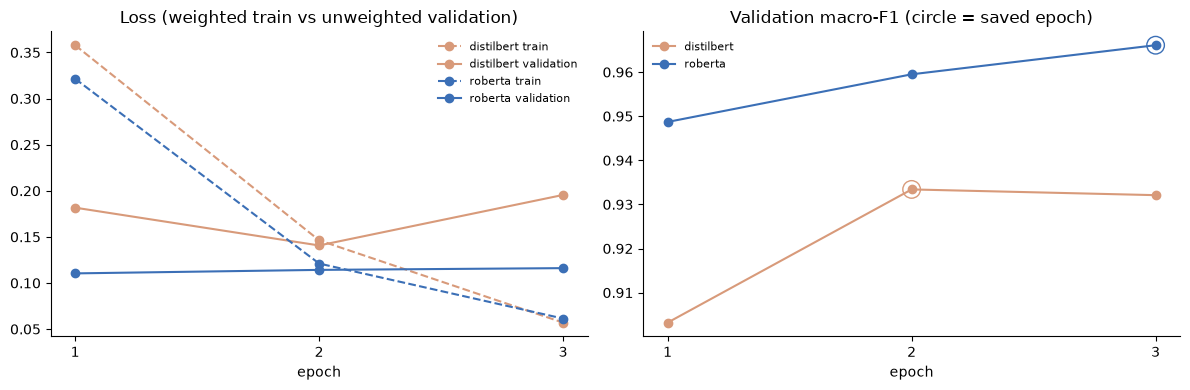

In [9]:
# Step 6b — training curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"distilbert": "#D89A7A", "roberta": "#3B6FB6"}
for key, info in FT_INFO.items():
    h = pd.DataFrame(info.get("history", []))
    if h.empty:
        continue
    axes[0].plot(h["epoch"], h["train_loss"], "--o", color=colors[key], label=f"{key} train")
    axes[0].plot(h["epoch"], h["val_loss"], "-o", color=colors[key], label=f"{key} validation")
    axes[1].plot(h["epoch"], h["val_Macro-F1"], "-o", color=colors[key], label=key)
    axes[1].scatter([info["best_epoch"]], [info["val_scores"]["Macro-F1"]], s=160,
                    facecolors="none", edgecolors=colors[key])
axes[0].set_title("Loss (weighted train vs unweighted validation)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Validation macro-F1 (circle = saved epoch)"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(); plt.show()

**Insight — training.**

| | DistilBERT | RoBERTa-base |
|---|---|---|
| Best epoch | 2 of 3 (stopped early) | 3 of 3 |
| Best validation macro-F1 | 0.9334 | **0.9661** |
| Best validation F1 (negative) | 0.8928 | **0.9457** |
| Training time (RTX 4060 Laptop, fp16) | 9.8 min | 18.0 min |

- **DistilBERT started to over-fit in epoch 3.** Training loss kept falling (0.146 → 0.057), but validation loss
  jumped from 0.141 to 0.196 and macro-F1 dipped slightly, so early stopping kept epoch 2. This is exactly what the
  validation split is for.
- **RoBERTa-base was still improving at epoch 3** (macro-F1 0.949 → 0.960 → 0.966), with validation loss flat at
  ~0.11. Its best epoch is the last one allowed, so a fourth epoch might add a little; three epochs is the usual
  budget for fine-tuning and was fixed before training.
- **After one epoch, RoBERTa-base (0.949) already beat DistilBERT's best (0.933)** and the SVM on the same
  validation rows (0.900, Section 7). The stronger pre-trained model matters more than extra epochs.
- Both models trained in **under 30 minutes on a laptop GPU**, the same job notebook 3 had to rule out on a CPU.

## 7. Validation results — choosing the model to deploy

The three **trained** models are the candidates: the Linear SVM and the two fine-tuned transformers. The zero-shot
models are benchmarks only, since they never learned from this data.

To compare like with like, the SVM is refitted here on the **training split only**, with notebook 3's tuned
settings (the saved model was refitted on all of Dataset A). The choice is made **on validation results, before
Dataset B is scored**, so the final test stays honest.

**Decision rule, fixed in advance:** take the cheapest model whose validation macro-F1 is within **0.005** of the
best. Cost order is known before any results: SVM (CPU, < 1 MB) < DistilBERT (66M) < RoBERTa-base (125M). A
bigger model has to be *clearly* better to justify its cost.

In [10]:
# Step 7 — validation scores of the three candidates

svm_final = joblib.load(os.path.join(DATA_DIR, "final_sentiment_model.joblib"))     # notebook 3's model
svm_val   = clone(svm_final).fit(df.loc[train_idx, ["clean_text"] + META_COLS], y_tr)
svm_val_pred = svm_val.predict(df.loc[val_idx, ["clean_text"] + META_COLS])

LABELS = {"svm": "Linear SVM + TF-IDF",
          **{k: c["label"] for k, c in ZERO_SHOT.items()},
          **{k: c["label"] for k, c in FINETUNE.items()}}

val_table = pd.DataFrame({LABELS["svm"]: scores(y_va, svm_val_pred),
                          **{LABELS[k]: FT_INFO[k]["val_scores"] for k in FINETUNE}}).T
val_table = val_table[["Accuracy", "Macro-F1", "F1 (neg)", "F1 (pos)"]]
print("Validation split (the same rows for all three):")
display(val_table)

Validation split (the same rows for all three):


,Accuracy,Macro-F1,F1 (neg),F1 (pos)
Linear SVM + TF-IDF,0.9363,0.8996,0.8389,0.9603
DistilBERT (fine-tuned),0.9582,0.9334,0.8928,0.9740
RoBERTa-base (fine-tuned),0.9785,0.9661,0.9457,0.9866


In [11]:
# Step 7b — apply the decision rule (validation only)

TOLERANCE      = 0.005
COST_ORDER     = ["svm", "distilbert", "roberta"]       # cheapest first
DEPLOY_OVERRIDE = None                                   # e.g. "roberta" to override the rule by hand

val_f1  = {k: float(val_table.loc[LABELS[k], "Macro-F1"]) for k in COST_ORDER}
best_f1 = max(val_f1.values())
DEPLOY_MODEL = DEPLOY_OVERRIDE or next(k for k in COST_ORDER if val_f1[k] >= best_f1 - TOLERANCE)
BEST_FT = max(FINETUNE, key=lambda k: val_f1[k])         # the stronger transformer, for the error analysis

for k in COST_ORDER:
    tag = "  <- deploy" if k == DEPLOY_MODEL else ""
    print(f"{LABELS[k]:<28} val macro-F1 {val_f1[k]:.4f}  (gap to best {best_f1 - val_f1[k]:.4f}){tag}")
print(f"\nModel to deploy: {LABELS[DEPLOY_MODEL]}   |   stronger fine-tuned model: {LABELS[BEST_FT]}")

Linear SVM + TF-IDF          val macro-F1 0.8996  (gap to best 0.0665)
DistilBERT (fine-tuned)      val macro-F1 0.9334  (gap to best 0.0327)
RoBERTa-base (fine-tuned)    val macro-F1 0.9661  (gap to best 0.0000)  <- deploy

Model to deploy: RoBERTa-base (fine-tuned)   |   stronger fine-tuned model: RoBERTa-base (fine-tuned)


## 8. Final test — every model on Dataset B

Each model scores Dataset B **once**:

| Model | Input | How it is run |
|---|---|---|
| Linear SVM | Cleaned text + style features | Notebook 3's saved model, trained on all of Dataset A |
| DistilBERT, RoBERTa-large (zero-shot) | Raw text, first 512 tokens | Notebook 3's cached predictions, so the numbers match notebook 3 exactly |
| DistilBERT, RoBERTa-base (fine-tuned) | Raw text, head + tail | The saved best epoch |

**Latency** is the time to classify **one review at a time, end to end** (cleaning or tokenising included),
averaged over a fixed random sample of Dataset B, after a few warm-up calls. It is measured on the CPU, where the
SVM runs, and on the GPU for the transformers. The GPU "batched" column is throughput when Dataset B is scored in
batches of 64, which is how a nightly catalogue job would run.

*Fairness note:* the SVM was refitted on all of Dataset A, while the transformers keep the epoch chosen on the
validation split, so they learned from 20% less data. That can only understate the transformers.

In [12]:
# Step 8 — helpers: zero-shot cache, latency timer, model size

import hashlib
TF_CACHE = os.path.join(DATA_DIR, "transformer_cache")
os.makedirs(TF_CACHE, exist_ok=True)

def zero_shot_labels(checkpoint, texts, model=None, tokenizer=None):
    # Notebook 3's cache: same key (model name + exact texts), so a hit returns notebook 3's exact predictions.
    key  = hashlib.md5(("|".join([checkpoint] + list(texts))).encode("utf-8")).hexdigest()
    path = os.path.join(TF_CACHE, f"{key}.json")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            payload = json.load(f)
        if len(payload["labels"]) == len(texts):
            print(f"  [cache HIT ] {checkpoint.split('/')[-1]}: notebook 3's predictions loaded")
            return np.array([1 if l == "POSITIVE" else 0 for l in payload["labels"]])
    print(f"  [cache MISS] {checkpoint.split('/')[-1]}: running inference on {len(texts):,} reviews")
    prob = P.transformer_proba(model, tokenizer, texts, DEVICE, EVAL_BATCH, USE_FP16,
                               MAX_LENGTH, head_tokens=MAX_LENGTH - 2)        # head-only, like notebook 3
    labels = ["POSITIVE" if p >= 0.5 else "NEGATIVE" for p in prob]
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"model": checkpoint, "n": len(texts), "labels": labels}, f)
    return (prob >= 0.5).astype(int)

def ms_per_review(fn, texts, device=None, warmup=5):
    # Average wall-clock milliseconds to classify one review at a time
    for t in texts[:warmup]:
        fn([t])
    sync = (lambda: torch.cuda.synchronize()) if (device is not None and device.type == "cuda") else (lambda: None)
    sync(); t0 = time.perf_counter()
    for t in texts:
        fn([t])
    sync()
    return (time.perf_counter() - t0) / len(texts) * 1000

def folder_mb(path):
    if not os.path.isdir(path):
        return float("nan")
    return sum(os.path.getsize(os.path.join(path, f)) for f in os.listdir(path)) / 1e6

_rng = np.random.default_rng(RANDOM_STATE)
lat_idx   = _rng.choice(len(B_text), size=min(LATENCY_SAMPLE, len(B_text)), replace=False)
lat_texts = [B_text[i] for i in lat_idx]
cpu_texts = lat_texts[:CPU_LATENCY_SAMPLE]

B_PRED, B_SCORE, LAT, SIZE, PARAMS = {}, {}, {}, {}, {}

In [13]:
# Step 8a — Linear SVM on Dataset B

B_PRED["svm"]  = svm_final.predict(XB)
B_SCORE["svm"] = svm_final.decision_function(XB)        # signed margin: > 0 positive
svm_fn = lambda texts: svm_final.predict(P.build_features(texts))   # cleaning included, as in predict.py
LAT["svm"] = {"CPU, 1 review (ms)": ms_per_review(svm_fn, lat_texts),
              "GPU, 1 review (ms)": np.nan, "GPU, batched (ms)": np.nan}
SIZE["svm"]   = os.path.getsize(os.path.join(DATA_DIR, "final_sentiment_model.joblib")) / 1e6
PARAMS["svm"] = svm_final.named_steps["clf"].coef_.size
print(f"Linear SVM: macro-F1 {f1_score(yB, B_PRED['svm'], average='macro'):.4f} | "
      f"{LAT['svm']['CPU, 1 review (ms)']:.1f} ms per review on the CPU")

Linear SVM: macro-F1 0.9136 | 17.8 ms per review on the CPU


In [14]:
# Step 8b — the four transformers on Dataset B, plus latency on GPU and CPU

def run_transformer(key, source, zero_shot):
    model, tokenizer, info = P.load_transformer(source, DEVICE)
    head = MAX_LENGTH - 2 if zero_shot else info.get("head_tokens", HEAD_TOKENS)
    PARAMS[key] = sum(p.numel() for p in model.parameters())
    SIZE[key]   = folder_mb(source) if os.path.isdir(source) else PARAMS[key] * 4 / 1e6   # fp32 weights

    # predictions on Dataset B (timed: batched throughput)
    t0 = time.perf_counter()
    if zero_shot:
        B_PRED[key] = zero_shot_labels(source, B_text, model, tokenizer)
        batched = np.nan if DEVICE.type != "cuda" else None
    else:
        B_SCORE[key] = P.transformer_proba(model, tokenizer, B_text, DEVICE, EVAL_BATCH, USE_FP16, MAX_LENGTH, head)
        B_PRED[key]  = (B_SCORE[key] >= 0.5).astype(int)
        batched = (time.perf_counter() - t0) / len(B_text) * 1000 if DEVICE.type == "cuda" else np.nan
    if batched is None:   # cached zero-shot predictions: time a batched pass separately
        t0 = time.perf_counter()
        P.transformer_proba(model, tokenizer, B_text, DEVICE, EVAL_BATCH, USE_FP16, MAX_LENGTH, head)
        torch.cuda.synchronize()
        batched = (time.perf_counter() - t0) / len(B_text) * 1000

    one = lambda texts, m=model, d=DEVICE: P.transformer_proba(m, tokenizer, texts, d, 1, USE_FP16, MAX_LENGTH, head)
    lat = {"GPU, 1 review (ms)": ms_per_review(one, lat_texts, DEVICE) if DEVICE.type == "cuda" else np.nan,
           "GPU, batched (ms)": batched, "CPU, 1 review (ms)": np.nan}
    if CPU_LATENCY_SAMPLE:
        model_cpu = model.to("cpu") if DEVICE.type == "cuda" else model
        one_cpu = lambda texts: P.transformer_proba(model_cpu, tokenizer, texts, torch.device("cpu"),
                                                    1, False, MAX_LENGTH, head)
        lat["CPU, 1 review (ms)"] = ms_per_review(one_cpu, cpu_texts, warmup=2)
    LAT[key] = lat
    P._transformers.clear()
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"{LABELS[key]:<28} macro-F1 {f1_score(yB, B_PRED[key], average='macro'):.4f} | "
          f"GPU {lat['GPU, 1 review (ms)']:.1f} ms | CPU {lat['CPU, 1 review (ms)']:.0f} ms per review")

for key, cfg in ZERO_SHOT.items():
    run_transformer(key, cfg["checkpoint"], zero_shot=True)
for key in FINETUNE:
    run_transformer(key, FT_SOURCE[key], zero_shot=False)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  [cache HIT ] distilbert-base-uncased-finetuned-sst-2-english: notebook 3's predictions loaded
DistilBERT (zero-shot)       macro-F1 0.8017 | GPU 11.7 ms | CPU 68 ms per review


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

  [cache HIT ] sentiment-roberta-large-english: notebook 3's predictions loaded
RoBERTa-large (zero-shot)    macro-F1 0.9166 | GPU 27.0 ms | CPU 389 ms per review


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT (fine-tuned)      macro-F1 0.9400 | GPU 10.1 ms | CPU 59 ms per review


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa-base (fine-tuned)    macro-F1 0.9611 | GPU 12.4 ms | CPU 109 ms per review


In [15]:
# Step 8c — the results table

ORDER = ["svm", "distilbert_zs", "roberta_large_zs", "distilbert", "roberta"]
KIND  = {"svm": "trained on reviews", "distilbert_zs": "zero-shot", "roberta_large_zs": "zero-shot",
         "distilbert": "fine-tuned on reviews", "roberta": "fine-tuned on reviews"}

def fmt_params(n):
    return f"{n/1e6:.0f}M" if n >= 1e6 else f"{n/1e3:.0f}k"

results = pd.DataFrame([{
    "Model": LABELS[k], "Type": KIND[k], "Parameters": fmt_params(PARAMS[k]),
    **scores(yB, B_PRED[k]),
    **{c: round(v, 1) for c, v in LAT[k].items()},
    "Size (MB)": round(SIZE[k], 1),
} for k in ORDER]).set_index("Model")

print(f"=== FINAL HELD-OUT RESULTS: Dataset B ({len(yB)} reviews) ===")
display(results)

if WRITE_DOCS:
    os.makedirs(os.path.join("docs", "results"), exist_ok=True)
    results.to_csv(os.path.join("docs", "results", "dataset_b_results.csv"))
    print("Saved -> docs/results/dataset_b_results.csv")

=== FINAL HELD-OUT RESULTS: Dataset B (843 reviews) ===


,Type,Parameters,Accuracy,Macro-F1,F1 (neg),F1 (pos),"CPU, 1 review (ms)","GPU, 1 review (ms)","GPU, batched (ms)",Size (MB)
Model,,,,,,,,,,
Linear SVM + TF-IDF,trained on reviews,20k,0.9442,0.9136,0.8622,0.9651,17.8,NaN,NaN,1.0
DistilBERT (zero-shot),zero-shot,67M,0.8446,0.8017,0.7095,0.8939,68.5,11.7,8.2,267.8
RoBERTa-large (zero-shot),zero-shot,355M,0.9431,0.9166,0.8696,0.9636,389.4,27.0,15.3,1421.4
DistilBERT (fine-tuned),fine-tuned on reviews,67M,0.9620,0.9400,0.9036,0.9764,59.1,10.1,6.6,268.5
RoBERTa-base (fine-tuned),fine-tuned on reviews,125M,0.9751,0.9611,0.9377,0.9844,109.1,12.4,6.5,502.2


Saved -> docs/results/dataset_b_results.csv


In [16]:
# Step 8d — full reports for the two fine-tuned models

for key in FINETUNE:
    print(f"{LABELS[key]} on Dataset B")
    print(classification_report(yB, B_PRED[key], target_names=["Negative (0)", "Positive (1)"]))

DistilBERT (fine-tuned) on Dataset B
              precision    recall  f1-score   support

Negative (0)       0.90      0.91      0.90       165
Positive (1)       0.98      0.97      0.98       678

    accuracy                           0.96       843
   macro avg       0.94      0.94      0.94       843
weighted avg       0.96      0.96      0.96       843

RoBERTa-base (fine-tuned) on Dataset B
              precision    recall  f1-score   support

Negative (0)       0.92      0.96      0.94       165
Positive (1)       0.99      0.98      0.98       678

    accuracy                           0.98       843
   macro avg       0.95      0.97      0.96       843
weighted avg       0.98      0.98      0.98       843



## 9. Comparison — accuracy against cost

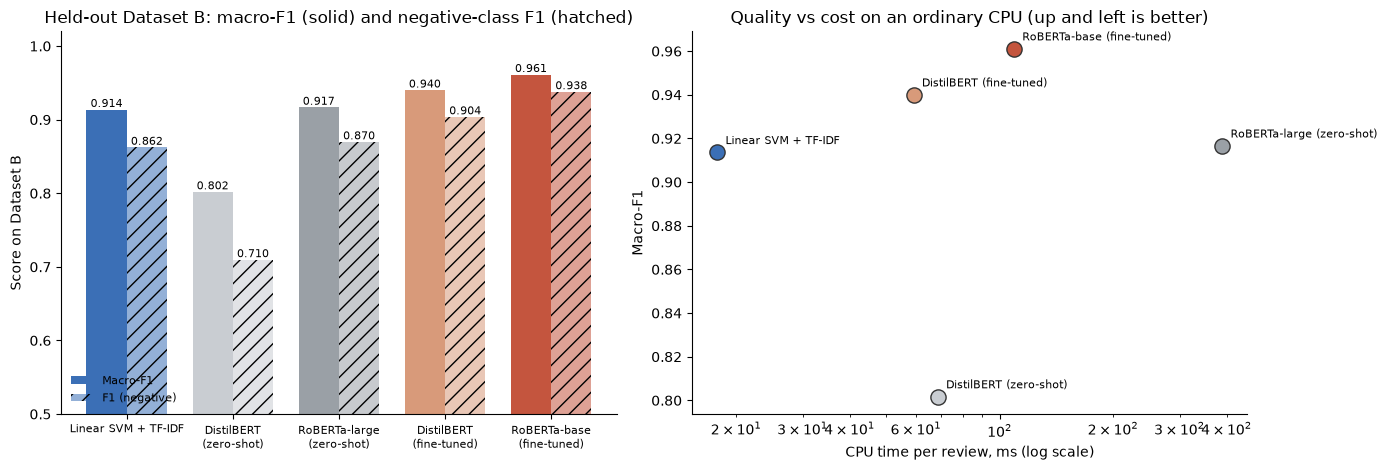

In [17]:
# Step 9 — macro-F1 / negative-class F1 by model, and accuracy vs CPU latency

palette = {"svm": "#3B6FB6", "distilbert_zs": "#C9CDD2", "roberta_large_zs": "#9AA0A6",
           "distilbert": "#D89A7A", "roberta": "#C4553E"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

x = np.arange(len(ORDER)); w = 0.38
mf1 = [results.loc[LABELS[k], "Macro-F1"] for k in ORDER]
nf1 = [results.loc[LABELS[k], "F1 (neg)"] for k in ORDER]
axes[0].bar(x - w/2, mf1, w, color=[palette[k] for k in ORDER], label="Macro-F1")
axes[0].bar(x + w/2, nf1, w, color=[palette[k] for k in ORDER], alpha=0.55, hatch="//", label="F1 (negative)")
for xi, (a, b) in enumerate(zip(mf1, nf1)):
    axes[0].annotate(f"{a:.3f}", (xi - w/2, a), ha="center", va="bottom", fontsize=8)
    axes[0].annotate(f"{b:.3f}", (xi + w/2, b), ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels([LABELS[k].replace(" (", "\n(") for k in ORDER], fontsize=8)
axes[0].set_ylim(0.5, 1.02); axes[0].set_ylabel("Score on Dataset B")
axes[0].set_title("Held-out Dataset B: macro-F1 (solid) and negative-class F1 (hatched)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")

for k in ORDER:
    lat = results.loc[LABELS[k], "CPU, 1 review (ms)"]
    if np.isnan(lat):
        continue
    acc = results.loc[LABELS[k], "Macro-F1"]
    axes[1].scatter(lat, acc, s=120, color=palette[k], edgecolor="#333", zorder=3)
    axes[1].annotate(LABELS[k], (lat, acc), xytext=(6, 6), textcoords="offset points", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("CPU time per review, ms (log scale)"); axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Quality vs cost on an ordinary CPU (up and left is better)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
if WRITE_DOCS:
    os.makedirs(os.path.join("docs", "images"), exist_ok=True)
    fig.savefig(os.path.join("docs", "images", "model_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

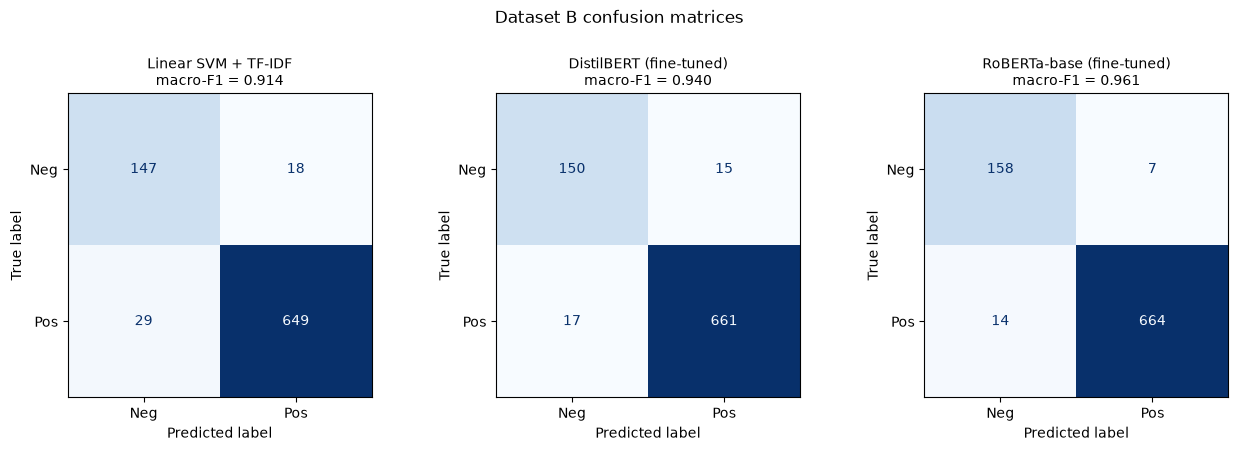

In [18]:
# Step 9b — confusion matrices: notebook 3's SVM vs the two fine-tuned transformers

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, key in zip(axes, ["svm", "distilbert", "roberta"]):
    ConfusionMatrixDisplay(confusion_matrix(yB, B_PRED[key]), display_labels=["Neg", "Pos"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{LABELS[key]}\nmacro-F1 = {f1_score(yB, B_PRED[key], average='macro'):.3f}", fontsize=10)
plt.suptitle("Dataset B confusion matrices", y=1.03)
plt.tight_layout()
if WRITE_DOCS:
    fig.savefig(os.path.join("docs", "images", "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Step 9c — write the results table into README.md (between the RESULTS_TABLE markers)

README_ROW_NAMES = {
    "svm":              "Linear SVM + TF-IDF (notebook 3)",
    "distilbert_zs":    "DistilBERT, pre-trained (zero-shot)",
    "roberta_large_zs": "RoBERTa-large, pre-trained (zero-shot)",
    "distilbert":       "DistilBERT, fine-tuned (notebook 4)",
    "roberta":          "RoBERTa-base, fine-tuned (notebook 4)",
}
README_COLS = [("Accuracy", "max"), ("Macro-F1", "max"), ("F1 (neg)", "max"),
               ("CPU, 1 review (ms)", "min"), ("GPU, 1 review (ms)", "min")]

def readme_table():
    def fmt(col, v):
        if pd.isna(v):
            return "—"
        if "ms" in col:
            return f"~{v:,.0f} ms" if v >= 10 else f"~{v:.1f} ms"
        return f"{v:.4f}"
    best = {c: (results[c].max() if how == "max" else results[c].min()) for c, how in README_COLS}
    lines = ["| Model | Accuracy | Macro-F1 | F1 (negative) | CPU, 1 review | GPU, 1 review |",
             "|---|---|---|---|---|---|"]
    for k in ORDER:
        r = results.loc[LABELS[k]]
        name = README_ROW_NAMES[k]
        if k == DEPLOY_MODEL:
            name = f"**{name}** (deployed)"
        cells = [f"**{fmt(c, r[c])}**" if (not pd.isna(r[c]) and r[c] == best[c]) else fmt(c, r[c])
                 for c, _ in README_COLS]
        lines.append("| " + " | ".join([name] + cells) + " |")
    gpu = FT_INFO[BEST_FT].get("gpu", "GPU")
    lines.append("")
    lines.append(f"*{len(yB)} held-out reviews. Latency = one review at a time, end to end; GPU = {gpu}, fp16. "
                 f"Generated by `04_Transformer_Finetuning.ipynb`.*")
    return "\n".join(lines)

table_md = readme_table()
display(Markdown(table_md))

START, END = "<!-- RESULTS_TABLE:START -->", "<!-- RESULTS_TABLE:END -->"
if UPDATE_README:
    with open("README.md", encoding="utf-8", newline="") as f:
        readme = f.read()
    if START in readme and END in readme:
        nl = "\r\n" if "\r\n" in readme else "\n"
        head, rest = readme.split(START, 1)
        _, tail = rest.split(END, 1)
        readme = head + START + nl + table_md.replace("\n", nl) + nl + END + tail
        with open("README.md", "w", encoding="utf-8", newline="") as f:
            f.write(readme)
        print("README.md results table updated.")
    else:
        print("RESULTS_TABLE markers not found in README.md; copy the table above by hand.")

| Model | Accuracy | Macro-F1 | F1 (negative) | CPU, 1 review | GPU, 1 review |
|---|---|---|---|---|---|
| Linear SVM + TF-IDF (notebook 3) | 0.9442 | 0.9136 | 0.8622 | **~18 ms** | — |
| DistilBERT, pre-trained (zero-shot) | 0.8446 | 0.8017 | 0.7095 | ~68 ms | ~12 ms |
| RoBERTa-large, pre-trained (zero-shot) | 0.9431 | 0.9166 | 0.8696 | ~389 ms | ~27 ms |
| DistilBERT, fine-tuned (notebook 4) | 0.9620 | 0.9400 | 0.9036 | ~59 ms | **~10 ms** |
| **RoBERTa-base, fine-tuned (notebook 4)** (deployed) | **0.9751** | **0.9611** | **0.9377** | ~109 ms | ~12 ms |

*843 held-out reviews. Latency = one review at a time, end to end; GPU = NVIDIA GeForce RTX 4060 Laptop GPU, fp16. Generated by `04_Transformer_Finetuning.ipynb`.*

README.md results table updated.


**Insight — fine-tuning wins clearly, and it wins on the negative class.**

| Dataset B (843 reviews) | Linear SVM | RoBERTa-large, zero-shot | DistilBERT, fine-tuned | RoBERTa-base, fine-tuned |
|---|---|---|---|---|
| Macro-F1 | 0.9136 | 0.9166 | 0.9400 | **0.9611** |
| F1 (negative) | 0.8622 | 0.8696 | 0.9036 | **0.9377** |
| Mistakes | 47 | 48 | 32 | **21** |
| CPU, 1 review | **~18 ms** | ~389 ms | ~59 ms | ~109 ms |
| Size | **1 MB** | 1,421 MB | 269 MB | 502 MB |

- **Training on the domain is what made the difference, not model size.** Zero-shot DistilBERT was the weakest
  model (0.802); the same architecture fine-tuned on anime reviews scores 0.940. Fine-tuned RoBERTa-base beats
  zero-shot RoBERTa-large (0.917) with about a third of the parameters, and is ~3.5× faster on a CPU.
- **The gain is concentrated on the negative class** (F1 +0.076 over the SVM): the minority class, and the one
  the business acts on. RoBERTa-base finds 96% of the negative reviews (recall 0.96) at 0.92 precision.
- **Validation and test agree.** The ranking on Dataset B matches validation (SVM < DistilBERT < RoBERTa-base),
  and RoBERTa-base's test macro-F1 (0.961) is close to its validation score (0.966), so choosing the epoch on
  validation did not over-fit it.
- **The price:** ~6× slower than the SVM on a CPU (109 vs 18 ms per review) and ~500× larger. On a GPU it takes
  ~12 ms per review one at a time, ~6.5 ms in batches. Even on a CPU, 109 ms is roughly 33,000 reviews an hour per
  process: plenty for daily review volumes, though not for scoring millions of reviews on cheap hardware.

## 10. Error analysis — what did fine-tuning fix?

Notebook 3 found that the SVM's confident mistakes were about **context, not vocabulary**: praise aimed at another
show, irony, reviewers arguing with someone else's opinion. A bag-of-words model can't see those; a transformer
reads word order and context, so this is where it should help. This section checks whether it does, comparing
the SVM with the stronger fine-tuned model (chosen on validation in Section 7).

In [20]:
# Step 10 — where the SVM and the fine-tuned transformer agree and disagree

ft = BEST_FT
svm_ok, ft_ok = B_PRED["svm"] == yB, B_PRED[ft] == yB
agree = pd.DataFrame({f"{LABELS[ft]} right": [int(( svm_ok &  ft_ok).sum()), int((~svm_ok &  ft_ok).sum())],
                      f"{LABELS[ft]} wrong": [int(( svm_ok & ~ft_ok).sum()), int((~svm_ok & ~ft_ok).sum())]},
                     index=["SVM right", "SVM wrong"])
print("Dataset B reviews, by which model got them right:")
display(agree)

by_rating = (pd.DataFrame({"rating": dfB["rating"].values,
                           **{LABELS[k]: (B_PRED[k] != yB) for k in ["svm", "distilbert", "roberta"]}})
             .groupby("rating").agg(["mean", "size"]))
err_tbl = pd.DataFrame({"reviews": by_rating[(LABELS["svm"], "size")]})
for k in ["svm", "distilbert", "roberta"]:
    err_tbl[f"{LABELS[k]} error %"] = (by_rating[(LABELS[k], "mean")] * 100).round(1)
print("\nError rate by original star rating:")
display(err_tbl)

Dataset B reviews, by which model got them right:


,RoBERTa-base (fine-tuned) right,RoBERTa-base (fine-tuned) wrong
SVM right,785,11
SVM wrong,37,10



Error rate by original star rating:


,reviews,Linear SVM + TF-IDF error %,DistilBERT (fine-tuned) error %,RoBERTa-base (fine-tuned) error %
rating,,,,
1,28,10.7,3.6,3.6
2,27,0.0,3.7,3.7
3,54,5.6,3.7,1.9
4,56,21.4,19.6,7.1
7,99,16.2,8.1,8.1
8,140,2.9,3.6,1.4
9,196,1.5,1.0,1.5
10,243,2.5,0.8,0.4


In [21]:
# Step 10b — examples: the SVM's most confident mistakes that the transformer gets right, and vice versa

def excerpt(t, n=230):
    return " ".join(str(t).split())[:n] + "..."

fixed = np.where(~svm_ok & ft_ok)[0]
fixed = fixed[np.argsort(-np.abs(B_SCORE["svm"][fixed]))][:4]
print(f"SVM WRONG, {LABELS[ft].upper()} RIGHT  (most confident SVM mistakes first)")
for i in fixed:
    print(f"  [{dfB['rating'].iat[i]} stars | SVM margin {B_SCORE['svm'][i]:+.2f} | "
          f"P(pos) {B_SCORE[ft][i]:.2f}] {excerpt(B_text[i])}")

broke = np.where(svm_ok & ~ft_ok)[0]
broke = broke[np.argsort(-np.abs(B_SCORE[ft][broke] - 0.5))][:3]
print(f"\nSVM RIGHT, {LABELS[ft].upper()} WRONG  (most confident transformer mistakes first)")
for i in broke:
    print(f"  [{dfB['rating'].iat[i]} stars | SVM margin {B_SCORE['svm'][i]:+.2f} | "
          f"P(pos) {B_SCORE[ft][i]:.2f}] {excerpt(B_text[i])}")

SVM WRONG, ROBERTA-BASE (FINE-TUNED) RIGHT  (most confident SVM mistakes first)
  [7 stars | SVM margin -1.14 | P(pos) 1.00] My "Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka" review. My ratings: Story: My Verdict, a poor 3. Art: My Verdict, a Good 7 Sound: My Verdict, a mediocre 5. ... Character: My Verdict, a poor 3. Enjoyment: My Verdict, ...
  [8 stars | SVM margin -0.96 | P(pos) 1.00] This show has a really sentimental place in my heart because it was one of the first animes that I’ve ever watched and was one of the first ones I was really obsessed with. Revisiting it over 10 years later I’ve realized how shock...
  [10 stars | SVM margin -0.83 | P(pos) 1.00] I figured since I'm currently watching season three, and will review it in the future, might as well get out my thoughts on the series in general. Talk about RACK CITY. Was this even an anime? It felt more like an episode of Girls...
  [4 stars | SVM margin +0.63 | P(pos) 0.01] I would like to let people know that 

**Insight — fine-tuning fixes most of the SVM's mistakes, but not the label noise.**

- **RoBERTa-base gets 37 of the SVM's 47 mistakes right** and makes 11 new ones: 21 errors in total, 55% fewer.
  Ten reviews defeat both models.
- **Errors still sit next to the dropped 5–6 band, but far fewer of them.** At 4 stars the error rate falls from
  21.4% to 7.1%, and at 7 stars from 16.2% to 8.1%. Everywhere else it is under 4%. What remains is mostly label
  noise: reviews whose star rating sits on the edge of "mixed".
- **What it fixes is context.** The SVM's most confident mistakes include a 7-star review written as a list of
  category scores ("Story: … a poor 3"), a nostalgic 8-star review about what shocked the reviewer on a rewatch,
  a joking 10-star review ("Was this even an anime?"), and a 4-star review that calls the show awesome before
  explaining the low score. Word counts see the positive or negative words; the transformer reads where the
  overall verdict lands.
- **What it gets wrong is mixed low ratings with a warm tone**: a 4-star "guilty pleasure", and a 1-star review
  that still gives the art 8/10. It is **completely confident** about these mistakes (P(positive) = 1.00).
  Fine-tuned transformers are often over-confident, which matters for the low-confidence safeguard in Section 14.
- **The two models fail differently.** They disagree on 48 reviews (6% of Dataset B), and those 48 contain
  37 of the SVM's errors and 11 of the transformer's. Disagreement between them is a useful signal in itself.

## 11. Recommendation — which model to deploy?

The model to deploy was chosen in Section 7 on validation results, with a rule fixed in advance. The table below
puts that choice next to everything a business would weigh: quality on unseen data, speed, size, hardware, and
whether the decision can be explained to the person who receives an alert.

In [22]:
# Step 11 — decision table

decision = pd.DataFrame({
    LABELS[k]: {
        "Validation macro-F1": val_f1[k],
        "Dataset B accuracy": results.loc[LABELS[k], "Accuracy"],
        "Dataset B macro-F1": results.loc[LABELS[k], "Macro-F1"],
        "Dataset B F1 (neg)": results.loc[LABELS[k], "F1 (neg)"],
        "CPU ms / review": results.loc[LABELS[k], "CPU, 1 review (ms)"],
        "GPU ms / review": results.loc[LABELS[k], "GPU, 1 review (ms)"],
        "Size (MB)": results.loc[LABELS[k], "Size (MB)"],
        "Retrain without a GPU": "yes, seconds" if k == "svm" else "no",
        "Explainable": "word weights" if k == "svm" else "not directly",
    } for k in COST_ORDER}).T
decision.insert(0, "Deploy?", ["<- deploy" if k == DEPLOY_MODEL else "" for k in COST_ORDER])
display(decision)
print(f"Rule from Section 7 (validation only): {LABELS[DEPLOY_MODEL]}")

,Deploy?,Validation macro-F1,Dataset B accuracy,Dataset B macro-F1,Dataset B F1 (neg),CPU ms / review,GPU ms / review,Size (MB),Retrain without a GPU,Explainable
Linear SVM + TF-IDF,,0.8996,0.9442,0.9136,0.8622,17.8,NaN,1.0,"yes, seconds",word weights
DistilBERT (fine-tuned),,0.9334,0.962,0.94,0.9036,59.1,10.1,268.5,no,not directly
RoBERTa-base (fine-tuned),<- deploy,0.9661,0.9751,0.9611,0.9377,109.1,12.4,502.2,no,not directly


Rule from Section 7 (validation only): RoBERTa-base (fine-tuned)


### Recommendation — deploy the fine-tuned RoBERTa-base, keep the SVM beside it

**Deploy RoBERTa-base (fine-tuned)** for the platform health dashboard. The rule fixed in Section 7 chose it on
validation (0.966 macro-F1, against 0.933 for DistilBERT and 0.900 for the SVM, far outside the 0.005
tolerance), and Dataset B confirms it: **97.5% accuracy, 0.961 macro-F1, and 0.938 F1 on the negative reviews**
that drive alerts.

**Is it worth the cost?** For this use case, yes.
- **The gain lands where the business acts.** Errors fall from 47 to 21 per 843 reviews, and negative-class F1
  from 0.862 to 0.938. A wrong "negative" is a false alarm about a title; a missed one hides a real problem. In
  Section 14 it avoids the SVM's false alarm on *Dandadan* on its own.
- **The speed is affordable at review volumes.** ~12 ms per review on a GPU, ~109 ms on a CPU. A title collects
  tens to hundreds of reviews a day, not millions, so one machine scores a whole catalogue's daily reviews in
  minutes.
- **What it costs:** a 502 MB model instead of 1 MB, a GPU to retrain (18 minutes on a laptop GPU), and
  decisions that can't be read off word weights.

**Keep the Linear SVM** beside it:
- **To explain decisions.** Its word weights show *why* a review reads as negative; the transformer can't.
- **Where there is no GPU, or volume is very high:** ~18 ms per review on a CPU, 6× faster, and it retrains in
  seconds.
- **As a second opinion.** The two models disagree on only 6% of reviews, and those reviews hold 11 of the
  transformer's 21 errors (Section 10).

**DistilBERT (fine-tuned) is the middle option:** 0.940 macro-F1, ~59 ms per review on a CPU and 269 MB. It's
the choice when there's no GPU but the SVM's accuracy isn't enough.

**Operational rule: send uncertain negatives to a human.** With the SVM, "uncertain" means a margin under 0.5.
The transformer is over-confident, even on its mistakes, so its probability alone flags very little (Section
14). With the transformer, **send reviews where it and the SVM disagree to a human instead**: checking 6% of
reviews would catch about half of its errors.

**In `predict.py`** the SVM stays the default, because it is the model that ships with the repository. The
fine-tuned transformer is one flag away (`--model roberta`) once it has been trained or downloaded from the Hub.

*Before fine-tuning (notebook 3), the recommendation was the Linear SVM: 94.4% accuracy, 0.914 macro-F1, matching
zero-shot RoBERTa-large at a fraction of the cost. Fine-tuning changed the answer because it raised the score by
a wide margin, not by 0.003.*

## 12. Save the models for prediction

All three trained models are now saved where `predict.py` looks for them:

| Model | Saved to | In the GitHub repo? |
|---|---|---|
| Linear SVM | `data/final_sentiment_model.joblib` (notebook 3) | Yes, under 1 MB |
| DistilBERT, fine-tuned | `models/distilbert-anime-sentiment/` | No: too large for GitHub's 100 MB file limit |
| RoBERTa-base, fine-tuned | `models/roberta-base-anime-sentiment/` | No: same reason |

Each transformer folder holds the weights (`model.safetensors`), the tokeniser, `training_info.json` (settings,
history, scores) and a model card (`README.md`). The cell below adds the Dataset B scores and the model card, then
reloads every model **through `predict.py`'s public API**, the same path another user would take.

**Sharing the transformers.** Others can get them without training in one of two ways: copy the `models/`
folders, or upload them to the Hugging Face Hub with the optional cell after this one and put the repo ids in
`HUB_MODEL_IDS` in `predict.py`. `predict.py` then downloads them on first use.

In [23]:
# Step 12 — add test scores + a model card to each fine-tuned model, then reload everything via predict.py

MODEL_CARD = '''---
language: en
license: {license}
base_model: {base}
pipeline_tag: text-classification
tags: [sentiment-analysis, anime, reviews]
---

# {title}

`{base}` fine-tuned to classify English anime reviews as **positive** (7-10 stars) or **negative** (1-4 stars).
Trained on {n_train:,} MyAnimeList reviews (notebook 4 of the Anime Review Sentiment Classifier project);
reviews rated 5-6 were excluded as mixed.

## Results on held-out reviews (Dataset B, {n_test} reviews)

| Accuracy | Macro-F1 | F1 (negative) | F1 (positive) |
|---|---|---|---|
| {acc:.4f} | {mf1:.4f} | {nf1:.4f} | {pf1:.4f} |

## Usage

Long reviews were cut to their first {head} and last {tail} tokens during training; do the same at
prediction time for the same accuracy. The project's `predict.py` does this for you:

```bash
python predict.py --model-path <this repo id or folder> "The animation was stunning!"
```

## Training

Best epoch {best_epoch} of {epochs_max}, learning rate {lr}, effective batch {eff_bs}, class-weighted
cross-entropy, fp16 mixed precision on {gpu}.

## Limitations

Trained only on popular titles' reviews, in English. Mixed (5-6 star) reviews were never seen. Sarcasm
and praise aimed at a different show can still fool it. The review text belongs to its authors on
MyAnimeList; this model is shared for non-commercial, educational use.
'''

for key in FINETUNE:
    src = FT_SOURCE[key]
    if not os.path.isdir(src):          # loaded from the Hub: nothing to write locally
        continue
    info_path = os.path.join(src, "training_info.json")
    info = P.load_training_info(src)
    info["test_scores_dataset_b"] = scores(yB, B_PRED[key])
    info["n_test"] = int(len(yB))
    with open(info_path, "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2)
    t = info["test_scores_dataset_b"]
    card = MODEL_CARD.format(
        license={"distilbert-base-uncased": "apache-2.0", "roberta-base": "mit"}.get(info["base_checkpoint"], "other"),
        base=info["base_checkpoint"], title=info["name"], n_train=info["n_train"], n_test=len(yB),
        acc=t["Accuracy"], mf1=t["Macro-F1"], nf1=t["F1 (neg)"], pf1=t["F1 (pos)"],
        head=info["head_tokens"], tail=info["max_length"] - info["head_tokens"] - 2,
        best_epoch=info["best_epoch"], epochs_max=info["epochs_max"], lr=info["lr"],
        eff_bs=info["batch_size"] * info["grad_accum"], gpu=info["gpu"])
    with open(os.path.join(src, "README.md"), "w", encoding="utf-8") as f:
        f.write(card)
    print(f"{key}: model card + test scores written to {src}  ({folder_mb(src):.0f} MB)")

# reload each model the way a user would, and classify two hand-written reviews
demo = ["The animation was stunning and the ending made me cry. Masterpiece!",
        "Boring, rushed and a total waste of time. Why did I watch this?"]
P._transformers.clear()
for name in ["svm", *FINETUNE]:
    model_arg = name if name == "svm" else FT_SOURCE[name]
    out = P.predict(demo, model=model_arg)
    print(f"\n{LABELS[name]}")
    for r in out:
        score = f"margin {r['score']:+.2f}" if name == "svm" else f"P(positive) {r['score']:.3f}"
        print(f"  {r['label']:<8} {score}  {r['text'][:60]}")
P._transformers.clear()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("\nFrom a terminal:")
print('  python predict.py "Great show!"                  # Linear SVM')
print('  python predict.py --model roberta "Great show!"  # fine-tuned RoBERTa-base')

distilbert: model card + test scores written to c:\Users\surgl\School\Anime_reviews_TSA\models\distilbert-anime-sentiment  (269 MB)
roberta: model card + test scores written to c:\Users\surgl\School\Anime_reviews_TSA\models\roberta-base-anime-sentiment  (502 MB)

Linear SVM + TF-IDF
  positive margin +0.88  The animation was stunning and the ending made me cry. Maste
  negative margin -2.24  Boring, rushed and a total waste of time. Why did I watch th


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


DistilBERT (fine-tuned)
  positive P(positive) 0.996  The animation was stunning and the ending made me cry. Maste
  negative P(positive) 0.003  Boring, rushed and a total waste of time. Why did I watch th


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


RoBERTa-base (fine-tuned)
  positive P(positive) 1.000  The animation was stunning and the ending made me cry. Maste
  negative P(positive) 0.001  Boring, rushed and a total waste of time. Why did I watch th

From a terminal:
  python predict.py "Great show!"                  # Linear SVM
  python predict.py --model roberta "Great show!"  # fine-tuned RoBERTa-base


In [24]:
# Step 12b (optional) — upload the fine-tuned models to the Hugging Face Hub so others can use them
#
# 1. Create a free account at huggingface.co and a WRITE access token (Settings -> Access Tokens)
# 2. Log in once, in a terminal:   huggingface-cli login      (or: hf auth login)
# 3. Set HF_USERNAME below and run this cell. The repos are created PUBLIC unless HF_PRIVATE = True.
# 4. Put the printed repo ids into HUB_MODEL_IDS in predict.py, then commit predict.py.
#
# Before publishing, note that the weights were trained on MyAnimeList reviews: see the README's
# "Data ethics" section. The model card states non-commercial, educational use.

HF_USERNAME = None          # e.g. "your-hf-username"
HF_PRIVATE  = False

if HF_USERNAME and not QUICK_RUN:
    from huggingface_hub import HfApi
    api = HfApi()
    for key in FINETUNE:
        repo_id = f"{HF_USERNAME}/{P.TRANSFORMER_MODELS[key]}"
        api.create_repo(repo_id, private=HF_PRIVATE, exist_ok=True)
        api.upload_folder(repo_id=repo_id, folder_path=FT_SOURCE[key],
                          commit_message="Upload fine-tuned model from 04_Transformer_Finetuning.ipynb")
        print(f"Uploaded -> https://huggingface.co/{repo_id}")
    print("\nNow set in predict.py:")
    print("HUB_MODEL_IDS = {")
    for key in FINETUNE:
        print(f'    "{key}": "{HF_USERNAME}/{P.TRANSFORMER_MODELS[key]}",')
    print("}")
else:
    print("Skipped: set HF_USERNAME to upload the fine-tuned models to the Hugging Face Hub.")

Skipped: set HF_USERNAME to upload the fine-tuned models to the Hugging Face Hub.


## 13. Challenges and lessons

| Challenge | What it changed |
|---|---|
| 4 : 1 class imbalance | Handled four ways — dropping the neutral band, stratified splits, class weights (in the SVM *and* the transformers' loss), ranking by macro-F1 — and still every model's main weakness |
| Removing character names | The first rule (≤ 2 shows) caught almost nothing, because sequels count as separate titles. Found only by checking the step's *output* |
| A plausible metric giving wrong answers | The "most distinctive words" ranking filled with names until a minimum-shows guard was added |
| How far to trust an external word list | Using the lexicon to *protect* words was tested and rejected, because it rescued title words. It verifies the threshold instead |
| Runtime | On a CPU, fine-tuning was ruled out and RoBERTa-large ran on Dataset B only. Moving to a GPU (this notebook) made fine-tuning practical: both models trained in under 30 minutes |
| Reviews longer than 512 tokens | 47% of reviews don't fit. Head + tail truncation keeps the opening and the verdict, and lives in `predict.py` so training and prediction cut text identically |
| 8 GB of GPU memory | fp16 mixed precision, batches of 8 for RoBERTa-base with gradient accumulation to an effective 16, and evaluation batches sorted by length |
| Over-fitting within a few epochs | DistilBERT's validation loss rose sharply in epoch 3 while its training loss kept falling. Early stopping on validation macro-F1 kept epoch 2 |
| An over-confident model | The fine-tuned transformer scores its own mistakes at P = 1.00, so the SVM's low-confidence rule doesn't carry over. Disagreement with the SVM is used as the review signal instead |
| A fair comparison | Same training / validation rows as notebook 3, the deployment rule fixed before Dataset B was scored, and the zero-shot results read from notebook 3's cache |
| Sharing large models | The fine-tuned weights exceed GitHub's 100 MB file limit, so they are kept out of git and can be shared through the Hugging Face Hub |

**Lessons**
- **Check outputs; don't assume the code did what was intended.** Several problems above only showed up in the printed results.
- **Preparation beats tuning.** Grid search changed nothing for the SVM; cleaning and name removal drove its performance.
- **Start simple, then make the complex model earn its place.** The SVM set a strong, cheap baseline, and the deployment rule only allowed a costlier model if it won clearly on validation. Fine-tuned RoBERTa-base did, by 0.066 macro-F1.
- **Training on the domain beats model size.** A fine-tuned 125M-parameter model beat a 355M-parameter model used zero-shot, and zero-shot DistilBERT was the worst model of all until it was fine-tuned.
- **Keep decisions traceable.** Raw data stays raw, the cleaning artifacts are frozen, and the transformer's truncation lives in one function used by both training and prediction.

## 14. Business scenario — the platform health dashboard

**Scenario.** Sarah is a content manager at a streaming platform. A newly licensed title starts collecting
reviews — text only, no ratings yet — and she needs to know within a day whether audiences like it, without
reading them.

| Indicator | Definition |
|---|---|
| **Catalogue Sentiment Score** | % of reviews classified positive |
| **Underperforming Content Alert** | Raised when negative sentiment exceeds **30%** |

Three titles from Dataset B are scored with their star ratings **withheld**; the real ratings are revealed
afterwards as a check. The dashboard is shown for two models side by side: notebook 3's Linear SVM, and the
deployed model (or, if the SVM is deployed, the stronger fine-tuned transformer).

**Low confidence**, used for the human-review rule: an SVM margin below 0.5, or a transformer probability
between 0.25 and 0.75 — the same rule `predict.py` uses.

In [25]:
# Step 14 - business scenario: the two platform-health indicators, for two models

DEMO_TITLES     = ["Clannad: After Story", "Dandadan", "Sword Art Online"]
ALERT_THRESHOLD = 0.30      # flag a title when negative sentiment passes 30%
DASH_MODELS     = ["svm", DEPLOY_MODEL if DEPLOY_MODEL != "svm" else BEST_FT]
PRIMARY         = DEPLOY_MODEL                                           # the deployed model drives the alerts

def confidence(key):
    # 0 = on the boundary. SVM: |margin|. Transformer: |2p - 1|. Below 0.5 counts as low confidence.
    return np.abs(B_SCORE[key]) if key == "svm" else np.abs(2 * B_SCORE[key] - 1)

rows, per_review = [], {}
for title in DEMO_TITLES:
    pos = np.where(dfB["anime_title"].values == title)[0]
    if len(pos) == 0:
        continue
    row = {"Title": title, "Reviews": len(pos)}
    for key in DASH_MODELS:
        pred = B_PRED[key][pos]
        neg_rate = float((pred == 0).mean())
        row[f"Positive % [{LABELS[key]}]"] = round((1 - neg_rate) * 100, 1)
        row[f"Status [{LABELS[key]}]"] = "*** ALERT ***" if neg_rate > ALERT_THRESHOLD else "healthy"
        per_review[(title, key)] = pd.DataFrame({
            "predicted":  np.where(pred == 1, "positive", "negative"),
            "confidence": confidence(key)[pos].round(2),
            "review": [excerpt(B_text[i], 90) for i in pos],
        })
    rows.append(row)

dashboard = pd.DataFrame(rows).set_index("Title")
print("=" * 90)
print("PLATFORM HEALTH DASHBOARD".center(90))
print(f"(alert threshold: negative sentiment above {ALERT_THRESHOLD:.0%})".center(90))
print("=" * 90)
display(dashboard)

status_col = f"Status [{LABELS[PRIMARY]}]"
flagged = dashboard[dashboard[status_col].str.contains("ALERT")]
print(f"\nTitles requiring attention today ({LABELS[PRIMARY]}): {len(flagged)} of {len(dashboard)}")
for title, r in flagged.iterrows():
    print(f"  - {title}: {100 - r[f'Positive % [{LABELS[PRIMARY]}]']:.1f}% negative across {r['Reviews']} reviews")

                                PLATFORM HEALTH DASHBOARD                                 
                     (alert threshold: negative sentiment above 30%)                      


,Reviews,Positive % [Linear SVM + TF-IDF],Status [Linear SVM + TF-IDF],Positive % [RoBERTa-base (fine-tuned)],Status [RoBERTa-base (fine-tuned)]
Title,,,,,
Clannad: After Story,9,88.9,healthy,100.0,healthy
Dandadan,12,58.3,*** ALERT ***,75.0,healthy
Sword Art Online,7,14.3,*** ALERT ***,14.3,*** ALERT ***



Titles requiring attention today (RoBERTa-base (fine-tuned)): 1 of 3
  - Sword Art Online: 85.7% negative across 7 reviews


In [26]:
# Step 14b - drill down into the flagged title closest to the threshold, as Sarah would

if not flagged.empty:
    worst = flagged[f"Positive % [{LABELS[PRIMARY]}]"].idxmax()
    for key in DASH_MODELS:
        tbl = per_review[(worst, key)]
        print(f"DRILL-DOWN: {worst}  -  {LABELS[key]}\n" + "-" * 90)
        display(tbl.sort_values("confidence", ascending=False))
        low_conf = tbl.query("predicted == 'negative' and confidence < 0.5")
        print(f"Negative predictions with confidence < 0.5 (flagged for human review): "
              f"{len(low_conf)} of {(tbl['predicted'] == 'negative').sum()}\n")
else:
    print(f"No title is flagged by {LABELS[PRIMARY]}.")

DRILL-DOWN: Sword Art Online  -  Linear SVM + TF-IDF
------------------------------------------------------------------------------------------


,predicted,confidence,review
3,negative,1.90,"Sword Art Online is a terrible, childish, fanf..."
1,negative,1.82,|This review contains minor spoilers of the sh...
6,positive,1.75,"While this anime isn't perfect, it sure as hel..."
4,negative,1.53,PART ONE EPISODES 1-14 Sword Art Online is one...
0,negative,1.07,"There will be spoilers. ""To escape, players mu..."
2,negative,0.44,"Hype Art Online, or HAO like everyone calls it..."
5,negative,0.17,"Ah, Sword Art Online...you had so much potenti..."


Negative predictions with confidence < 0.5 (flagged for human review): 2 of 6

DRILL-DOWN: Sword Art Online  -  RoBERTa-base (fine-tuned)
------------------------------------------------------------------------------------------


,predicted,confidence,review
0,negative,1.00,"There will be spoilers. ""To escape, players mu..."
1,negative,1.00,|This review contains minor spoilers of the sh...
2,negative,1.00,"Hype Art Online, or HAO like everyone calls it..."
3,negative,1.00,"Sword Art Online is a terrible, childish, fanf..."
5,negative,1.00,"Ah, Sword Art Online...you had so much potenti..."
6,positive,1.00,"While this anime isn't perfect, it sure as hel..."
4,negative,0.99,PART ONE EPISODES 1-14 Sword Art Online is one...


Negative predictions with confidence < 0.5 (flagged for human review): 0 of 6



VALIDATION - predictions against the withheld star ratings


,Actual positive %,Mean star rating,Predicted positive % [Linear SVM + TF-IDF],Correct [Linear SVM + TF-IDF],Predicted positive % [RoBERTa-base (fine-tuned)],Correct [RoBERTa-base (fine-tuned)]
Title,,,,,,
Clannad: After Story,100.0,9.6,88.9,8 of 9,100.0,9 of 9
Dandadan,75.0,7.3,58.3,10 of 12,75.0,12 of 12
Sword Art Online,14.3,4.1,14.3,7 of 7,14.3,7 of 7


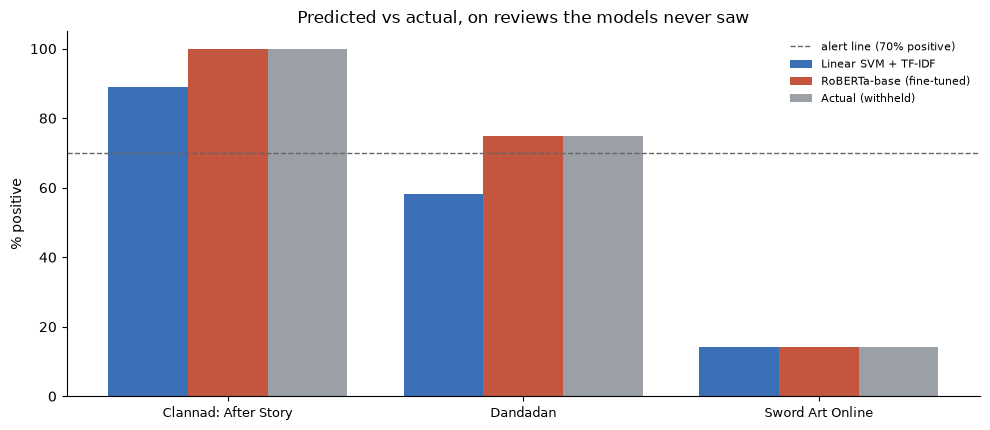

In [27]:
# Step 14c - validation: reveal the real ratings the models never saw

check = []
for title in dashboard.index:
    pos = np.where(dfB["anime_title"].values == title)[0]
    row = {"Title": title,
           "Actual positive %": round(float((yB[pos] == 1).mean()) * 100, 1),
           "Mean star rating":  round(float(dfB["rating"].values[pos].mean()), 1)}
    for key in DASH_MODELS:
        row[f"Predicted positive % [{LABELS[key]}]"] = round(float((B_PRED[key][pos] == 1).mean()) * 100, 1)
        row[f"Correct [{LABELS[key]}]"] = f"{int((B_PRED[key][pos] == yB[pos]).sum())} of {len(pos)}"
    check.append(row)
validation = pd.DataFrame(check).set_index("Title")
print("VALIDATION - predictions against the withheld star ratings")
display(validation)

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(validation)); w = 0.27
bars = [(f"Predicted positive % [{LABELS[k]}]", LABELS[k], palette[k]) for k in DASH_MODELS]
bars.append(("Actual positive %", "Actual (withheld)", "#9AA0A6"))
for i, (col, lab, colr) in enumerate(bars):
    ax.bar(x + (i - 1) * w, validation[col], w, label=lab, color=colr)
ax.axhline(100 - ALERT_THRESHOLD * 100, ls="--", color="#666", lw=1,
           label=f"alert line ({100 - ALERT_THRESHOLD*100:.0f}% positive)")
ax.set_xticks(x); ax.set_xticklabels([t[:22] for t in validation.index], fontsize=9)
ax.set_ylabel("% positive"); ax.set_ylim(0, 105)
ax.set_title("Predicted vs actual, on reviews the models never saw")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Insight — the alert works, and the fine-tuned model avoids the false alarm

| Title | Actual positive | Linear SVM | RoBERTa-base (fine-tuned) |
|---|---|---|---|
| Clannad: After Story | 100% | 88.9%, healthy — correct | 100%, healthy — correct |
| Dandadan | 75.0% | 58.3%, **flagged — false alarm** | 75.0%, healthy — correct |
| Sword Art Online | 14.3% | 14.3%, flagged — correct | 14.3%, flagged — correct |

**With the SVM, the low-confidence rule resolves the false alarm.** For *Dandadan*, the three confident negative
predictions were all correct, and the two low-confidence ones (< 0.5) were both wrong: slang like *"the reason
why I fw this anime so bad"*, and *"so beautiful to see my beloved weird manga"*. If Sarah checks those two by
hand, *Dandadan* drops from 41.7% to 25% negative — below the 30% threshold — and the alert clears itself.

**The fine-tuned transformer gets all 28 reviews right.** It predicts each title's real positive share
exactly, so *Dandadan* is never flagged and the correct alert on *Sword Art Online* stays. It reads the slang and
context that tripped the SVM, so the false alarm doesn't happen in the first place.

**But its confidence can't be used the same way.** It scores almost every review at 0.99–1.00, so the
low-confidence check flagged none of the 6 negative *Sword Art Online* reviews (the SVM flagged 2). That's harmless
here, because all its predictions were right, but Section 10 showed it is just as sure of its mistakes. With the
transformer, the reviews to check by hand are the ones where it and the SVM disagree.

*Limitations:* only 7–12 reviews per title here, so each error moves a percentage by 8–14 points. The 30%
threshold is a business choice; the precision-recall curve in notebook 3 (Section 7) is how you would set it
deliberately.

## 15. Aspect analysis — *what* are reviewers complaining about?

The dashboard says *how many* reviews are negative, not *why*. The business question is which elements —
pacing, adaptation, story, animation — drive satisfaction and complaints.

**Attempt 1, abandoned: read the SVM's bigram weights.** Phrases contradicted their own meaning (*art good*
−0.76, *great pace* −0.34). With 20,000 correlated features, individual coefficients are not stable
estimates (*multicollinearity*), even though the model as a whole is accurate. A transformer offers no weights to
read at all.

**Attempt 2, used: sentence-level lexicon scoring.** Reviews are split into sentences, and for each sentence
mentioning an aspect, positive and negative words from the Hu & Liu lexicon are counted. Working per sentence
means *"gorgeous animation, but the story was a mess"* credits the praise to animation and the criticism to
story. *Limitation:* it links sentiment by sentence, not by grammar, so it is an approximation rather than full
aspect-based sentiment analysis. It doesn't use any classifier, so it is the same whichever model is deployed.

In [28]:
# Step 15 - aspect sentiment via sentence-level lexicon scoping

import re
import nltk
nltk.download("opinion_lexicon", quiet=True)
from nltk.corpus import opinion_lexicon

POS_WORDS = set(opinion_lexicon.positive())
NEG_WORDS = set(opinion_lexicon.negative()) | {
    "rushed", "bland", "generic", "soulless", "unfunny", "overrated", "mediocre", "boring"}

ASPECT_TERMS = {
    "Story / writing": {"story", "stories", "plot", "writing", "narrative", "premise",
                        "twist", "ending", "plotline"},
    "Animation / art": {"animation", "animations", "art", "artwork", "visual", "visuals",
                        "cgi", "artstyle", "animated"},
    "Characters":      {"character", "characters", "cast", "protagonist", "villain",
                        "characterisation", "characterization"},
    "Pacing":          {"pacing", "pace", "rushed", "filler", "fillers", "slow", "dragged"},
    "Music / sound":   {"music", "ost", "soundtrack", "soundtracks", "voice", "sound",
                        "dub", "dubbed", "seiyuu"},
    "Adaptation":      {"adaptation", "adaptations", "adapted", "manga", "source"},
}

SENT_SPLIT = re.compile(r"[.!?]+")
WORD_RE    = re.compile(r"[a-z']+")

def scan_aspects(texts):
    # Count positive / negative lexicon words in sentences that mention each aspect
    st = {a: {"sentences": 0, "pos": 0, "neg": 0} for a in ASPECT_TERMS}
    for text in texts:
        for sentence in SENT_SPLIT.split(str(text).lower()):
            toks = set(WORD_RE.findall(sentence))
            if not toks:
                continue
            p, n = len(toks & POS_WORDS), len(toks & NEG_WORDS)
            if p == 0 and n == 0:
                continue                          # no sentiment expressed in this sentence
            for aspect, terms in ASPECT_TERMS.items():
                if toks & terms:
                    st[aspect]["sentences"] += 1
                    st[aspect]["pos"] += p
                    st[aspect]["neg"] += n
    return st

stats = scan_aspects(df["review_text"].dropna().astype(str))
rows = []
for a, s in stats.items():
    total = s["pos"] + s["neg"]
    rows.append({
        "Aspect": a,
        "Sentences discussing it": s["sentences"],
        "Positive words": s["pos"],
        "Negative words": s["neg"],
        "% negative": round(s["neg"] / total * 100, 1) if total else None,
    })
aspect_tbl = pd.DataFrame(rows).sort_values("% negative", ascending=False)

print("ASPECT SENTIMENT - sentence-level, Hu & Liu lexicon")
print("higher % negative = reviewers criticise this aspect more when they raise it\n")
display(aspect_tbl)

ASPECT SENTIMENT - sentence-level, Hu & Liu lexicon
higher % negative = reviewers criticise this aspect more when they raise it



,Aspect,Sentences discussing it,Positive words,Negative words,% negative
3,Pacing,7188,8673,10757,55.4
0,Story / writing,49212,65615,58604,47.2
2,Characters,61794,89189,59845,40.2
5,Adaptation,6915,9899,5841,37.1
1,Animation / art,23540,40398,15355,27.5
4,Music / sound,20385,33976,11484,25.3


In [29]:
# Step 15b - what the criticism actually sounds like

# Selecting example sentences needs more care than the aggregate counts. Two filters
# are applied so the examples are genuine criticism of the work:
#   1. the sentence must contain an explicit EVALUATION word ("issues", "poor", "bland"),
#      which excludes plot description that merely uses dark vocabulary
#   2. that evaluation word must not be negated ("not bad", "no problems")
CRITICISM = {"issue", "issues", "problem", "problems", "bad", "poor", "poorly", "weak",
             "boring", "bored", "dull", "lazy", "rushed", "mess", "messy", "worst",
             "terrible", "awful", "disappointing", "disappointed", "flaw", "flaws",
             "flawed", "mediocre", "bland", "generic", "waste", "ruined", "ruin",
             "drags", "dragged", "draggy", "confusing", "nonsensical", "wasted"}
NEGATORS = {"not", "no", "n't", "never", "nothing", "without", "hardly", "barely", "isn"}
NEGATED_PHRASES = ("not bad", "no problem", "not the case", "nothing wrong", "not saying",
                   "not only", "far from bad")

def is_genuine_criticism(tokens, sentence):
    # Sentence contains at least one un-negated evaluation word
    if any(p in sentence for p in NEGATED_PHRASES):
        return False
    marks = [i for i, t in enumerate(tokens) if t in CRITICISM]
    if not marks:
        return False
    return any(not (set(tokens[max(0, i-4):i]) & NEGATORS) for i in marks)

examples = {a: [] for a in ASPECT_TERMS}
for text in df["review_text"].dropna().astype(str):
    for sentence in SENT_SPLIT.split(text.lower()):
        toks = WORD_RE.findall(sentence)
        tset = set(toks)
        if not tset or not is_genuine_criticism(toks, sentence):
            continue
        if len(tset & NEG_WORDS) <= len(tset & POS_WORDS):
            continue                                  # must be net negative
        for aspect, terms in ASPECT_TERMS.items():
            if (tset & terms) and len(examples[aspect]) < 3 and 45 < len(sentence) < 185:
                examples[aspect].append(sentence.strip())

pct = aspect_tbl.set_index("Aspect")["% negative"]
for aspect in aspect_tbl["Aspect"]:
    if examples[aspect]:
        print(f"\n{aspect}  ({pct[aspect]}% negative)")
        for s in examples[aspect]:
            print(f'   "{s}"')


Pacing  (55.4% negative)
   "there are some other problems, such as pacing issues where the series just grinds to a screeching halt and drags on for a fair bit"
   "6 i'm sorry, i really am, but there are fundamental structure and pacing issues with aot"
   "[end spoiler] there are also general pacing issues: it feels slow, yet we aren't given time to get to know the characters so when the inevitably die, it's hard to really care"

Story / writing  (47.2% negative)
   "the story breaks the mold of generic revenge story and adds things like conspiracy and thriller aspects that propels the experience"
   "the story literally goes no where, the characters become stale and boring, and the main character, who was a thorough badass, actually regresses into an indecisive child"
   "anyways, here's my problem with the story pacing"

Characters  (40.2% negative)
   "this is a huge problem in a series where death and survival are the main aspects, and a character’s death has no impact unless th

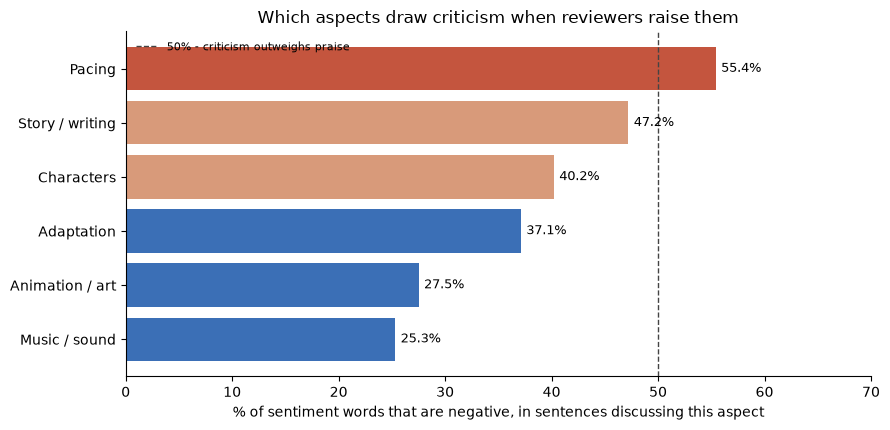

In [30]:
# Step 15c - the chart Sarah would read

fig, ax = plt.subplots(figsize=(9, 4.4))
d = aspect_tbl.set_index("Aspect")["% negative"]
colors = ["#C4553E" if v >= 50 else ("#D89A7A" if v >= 40 else "#3B6FB6") for v in d]
ax.barh(d.index[::-1], d.values[::-1], color=colors[::-1])
ax.axvline(50, ls="--", color="#444", lw=1, label="50% - criticism outweighs praise")
ax.set_xlabel("% of sentiment words that are negative, in sentences discussing this aspect")
ax.set_xlim(0, 70)
ax.set_title("Which aspects draw criticism when reviewers raise them")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
for yy, v in enumerate(d.values[::-1]):
    ax.annotate(f"{v}%", (v, yy), va="center", xytext=(4, 0),
                textcoords="offset points", fontsize=9)
plt.tight_layout()
if WRITE_DOCS:
    fig.savefig(os.path.join("docs", "images", "aspect_sentiment.png"), dpi=150, bbox_inches="tight")
plt.show()

### Insight — pacing is the complaint; animation and music are the praise

| Aspect | Sentences | % negative |
|---|---|---|
| **Pacing** | 7,188 | **55.4%** — the only aspect where criticism outweighs praise |
| Story / writing | 49,212 | 47.2% — divides audiences |
| Characters | 61,794 | 40.2% |
| Adaptation | 6,915 | 37.1% |
| Animation / art | 23,540 | 27.5% |
| Music / sound | 20,385 | **25.3%** — the least criticised |

**Business takeaway:** when evaluating a licence, check the episode count against the source material — a
rushed adaptation is the most likely cause of negative sentiment. Production values (animation, music) are
rarely the problem.

*Limitations:* plot summaries use dark vocabulary (*"a titan rips…"*) that inflates the story and character
figures, which if anything widens pacing's lead; negation is only handled approximately.

### 15b. Per-title breakdown

Each dashboard title's aspect scores are compared with the catalogue average, because what matters is
whether a title draws **more** criticism than usual. This uses every review held for the title (Dataset A +
B), not just B: it is a text analysis that never trains or predicts with a model, so the held-out rule does
not apply, and 7–12 reviews would be too few. Aspects with fewer than 10 sentences are suppressed.

In [31]:
# Step 15d - per-title aspect breakdown vs the catalogue baseline

MIN_SENTENCES = 10          # below this the percentage is too noisy to report

# every review we hold for a title, from both Dataset A and Dataset B
all_reviews = pd.concat([df[["anime_title", "review_text"]],
                         dfB[["anime_title", "review_text"]]], ignore_index=True)
baseline = aspect_tbl.set_index("Aspect")["% negative"]

per_title = {}
for title in DEMO_TITLES:
    sub = all_reviews[all_reviews["anime_title"] == title]
    if sub.empty:                     # title absent, e.g. after a reduced scrape
        continue
    st  = scan_aspects(sub["review_text"].dropna())
    rows, dropped = [], []
    for aspect, s in st.items():
        total = s["pos"] + s["neg"]
        if s["sentences"] < MIN_SENTENCES or total == 0:
            dropped.append(f"{aspect} ({s['sentences']})")
            continue
        pct_neg = s["neg"] / total * 100
        rows.append({"Aspect": aspect,
                     "Sentences": s["sentences"],
                     "% negative": round(pct_neg, 1),
                     "Catalogue avg": baseline[aspect],
                     "Difference": round(pct_neg - baseline[aspect], 1)})
    per_title[title] = (len(sub), pd.DataFrame(rows).sort_values("Difference", ascending=False),
                        dropped)

status = dashboard[status_col]
for title, (n_rev, tbl, dropped) in per_title.items():
    print("=" * 78)
    print(f"{title}   |   {n_rev} reviews held   |   dashboard ({LABELS[PRIMARY]}): "
          f"{status.get(title, 'not in Dataset B')}")
    print("=" * 78)
    display(tbl)
    if dropped:
        print(f"   suppressed, under {MIN_SENTENCES} sentences: {', '.join(dropped)}")
    print()

Clannad: After Story   |   93 reviews held   |   dashboard (RoBERTa-base (fine-tuned)): healthy


,Aspect,Sentences,% negative,Catalogue avg,Difference
5,Adaptation,15,41.7,37.1,4.6
1,Animation / art,161,24.5,27.5,-3.0
4,Music / sound,169,21.1,25.3,-4.2
2,Characters,417,33.8,40.2,-6.4
0,Story / writing,687,37.6,47.2,-9.6
3,Pacing,32,39.2,55.4,-16.2



Dandadan   |   85 reviews held   |   dashboard (RoBERTa-base (fine-tuned)): healthy


,Aspect,Sentences,% negative,Catalogue avg,Difference
1,Animation / art,112,32.2,27.5,4.7
0,Story / writing,183,50.4,47.2,3.2
2,Characters,158,43.1,40.2,2.9
3,Pacing,23,55.3,55.4,-0.1
4,Music / sound,43,23.7,25.3,-1.6
5,Adaptation,40,34.7,37.1,-2.4



Sword Art Online   |   80 reviews held   |   dashboard (RoBERTa-base (fine-tuned)): *** ALERT ***


,Aspect,Sentences,% negative,Catalogue avg,Difference
1,Animation / art,218,36.9,27.5,9.4
2,Characters,541,49.4,40.2,9.2
0,Story / writing,439,55.0,47.2,7.8
3,Pacing,95,61.4,55.4,6.0
4,Music / sound,138,24.5,25.3,-0.8
5,Adaptation,13,29.6,37.1,-7.5


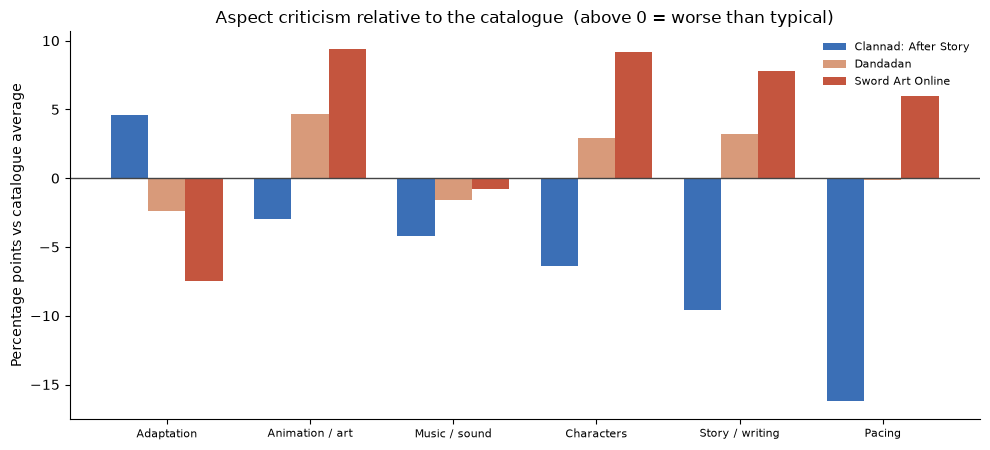

In [32]:
# Step 15e - the same comparison as one chart

frames = []
for title, (_, tbl, _) in per_title.items():
    frames.append(tbl.set_index("Aspect")["Difference"].rename(title))
diff = pd.concat(frames, axis=1)

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(diff.index)); w = 0.26
title_palette = ["#3B6FB6", "#D89A7A", "#C4553E"]
for i, col in enumerate(diff.columns):
    ax.bar(x + (i - 1) * w, diff[col].values, w, label=col[:22], color=title_palette[i % 3])
ax.axhline(0, color="#444", lw=1)
ax.set_xticks(x); ax.set_xticklabels(diff.index, fontsize=8)
ax.set_ylabel("Percentage points vs catalogue average")
ax.set_title("Aspect criticism relative to the catalogue  (above 0 = worse than typical)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Insight — the aspect profile is an independent second opinion

| Aspect (points vs catalogue) | Clannad *(healthy)* | Dandadan *(flagged by the SVM)* | Sword Art Online *(flagged)* |
|---|---|---|---|
| Animation / art | −3.0 | +4.7 | **+9.4** |
| Characters | −6.4 | +2.9 | **+9.2** |
| Story / writing | −9.6 | +3.2 | **+7.8** |
| Pacing | **−16.2** | −0.1 | **+6.0** |
| Music / sound | −4.2 | −1.6 | −0.8 |
| Adaptation | +4.6 | −2.4 | −7.5 |

- **Sword Art Online** is worse than typical on four aspects — a broad, real problem, matching its correct alert.
- **Clannad** is better than typical almost everywhere, most of all on pacing.
- **Dandadan** sits within ~5 points of average on everything — no real problem, which agrees that the SVM's
  alert was a false alarm (the fine-tuned model didn't raise it).

The aspect analysis never uses a classifier, so two independent methods agreeing on *Sword Art Online* and
disagreeing on *Dandadan* is stronger evidence than either alone. **Rule of thumb:** flagged *and* an aspect
clearly above average → investigate that aspect; flagged but every aspect near average → apply the
low-confidence check before escalating.

*Reliability:* Adaptation rests on only 13–40 sentences per title, so treat that row as indicative.

---
**End of the pipeline.** 1. Scraping → 2. Data Preparation → 3. Modelling & Evaluation → **4. Fine-tuning,
Comparison & Business**. To classify new reviews with any of the trained models, see `predict.py` and the README.